# Decomposing goal-directedness and directional precision in sensory-deprived echolocating bats during homing

Echolocating bats can return to familiar destinations after being displaced over kilometer distances. Which senses make this possible, and how does their navigation change when some of those senses are impaired? [Goldshtein et al. (2024)](https://doi.org/10.1126/science.adn6269) investigated these questions by translocating Kuhl's pipistrelles and tracking their flights under visual, magnetic, and olfactory manipulations. Bats generally homed successfully despite sensory deprivation, supporting the robustness of navigation with echolocation. Successful arrival nevertheless leaves open whether the bats traveled as directly and precisely as the controls.

A flight can contain both exploratory movement and sustained travel toward the goal. Imagine two bats that eventually fly equally straight toward home, but one first spends a longer part of its route searching. If we summarize all their bearings with a single concentration parameter, the second bat can appear less precise even though its directed travel is just as precise. A broad distribution of bearings can therefore reflect either imprecise homing or a mixture of precise homing and undirected exploration. Those explanations have different biological implications.

The original study separated an initial localization period from later homing using features such as straightness and heading. That helps focus on a particular phase of navigation, but introduces a tradeoff for treatment comparisons. If a sensory manipulation changes straightness or approach to the goal, it may also change which parts of the flight qualify as “homing.” Comparing only the selected segments can then partly reflect the selection rule. This is the problem of **post-treatment selection**: observations are selected using a feature that the treatment itself may affect.

Here we retain the full set of usable bearings and let a **von Mises–uniform mixture** describe directed travel alongside effectively undirected exploration. The von Mises component represents goal-directed travel, or exploitation; the uniform component represents wandering or search, or exploration. We use **goal-directedness** to mean the proportion of bearings assigned to directed travel. **Directional precision** describes how tightly those bearings cluster around their preferred direction. Sensory deprivation could affect either feature without changing the other. The mean direction is also estimated, so a consistent directional bias relative to the goal can be distinguished from a loss of precision.


## Setup

Select the R (`ir`) kernel and follow the [R setup](../getting-started-r.md)
page for the environment and kernel prerequisites; the first code cell
checks the pinned packages and CmdStan and stops with a pointer there
if the one-time setup has not been run. Run the cells in order.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "readxl", "sf",
  "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork",
  "curl", "png")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c("brms", "posterior", "loo", "circular", "readxl", "sf", "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork", "cmdstanr"),
    function(p) as.character(packageVersion(p)), character(1)))
versions


R          brms     posterior           loo      circular 
      "4.5.3"      "2.23.0"       "1.7.1" "2.10.1.9000"       "0.5.2" 
       readxl            sf     geosphere        Matrix       ggplot2 
      "1.6.0"       "1.1.3"       "1.6.8"       "1.7.6"       "4.0.3" 
         ragg     IRdisplay     patchwork      cmdstanr 
      "1.5.2"         "1.1"       "1.3.2"       "0.9.0"

In [3]:
suppressPackageStartupMessages({
  library(brms)
  library(posterior)
  library(loo)
  library(circular)
  library(readxl)
  library(sf)
  library(geosphere)
  library(Matrix)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}

source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))
source(file.path(repo_root, "R", "unwrap_helpers.R"))
source(file.path(repo_root, "notebooks_r", "goldshtein_bats_plots.R"))
source(file.path(repo_root, "notebooks_r", "goldshtein_bats_posthoc.R"))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



In [5]:
FIG_DIR <- file.path(repo_root, "figures", "goldshtein_bats")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
# Render PNGs for inline display; keep vector PDFs alongside them.
# save_figure comes from the shared helpers. show_figure is kept local
# (overriding the shared copy) because this study's individual PPC grid is a
# gtable with a hand-drawn legend row, which must be drawn through the grid
# engine rather than print() - a plain print leaves the device blank.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  # gtable objects (the individual PPC grid carries a hand-drawn
  # legend row) print via the grid engine rather than print();
  # a plain print leaves the device blank.
  if (inherits(plot, "gtable")) grid::grid.draw(plot) else print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}

theme_set(theme_minimal(base_size = 12))


In [6]:
SEED <- 123
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
ITER <- if (quick_run) 3000L else 4000L
WARMUP <- if (quick_run) 1500L else 2000L
# These are local execution budgets, not convergence claims. The hard
# diagnostic gates below apply to both budgets (R-hat < 1.01 everywhere;
# bulk ESS > 400 on every parameter on the full budget, with the quick
# budget taking a ~100-ESS-per-chain floor on weak per-animal offsets -
# see diagnose_fit). The quick budget runs the same 4-chain topology as
# the full budget at 75% of the draws (1500 post-warmup per chain, 6000
# total): at the old quick budget (2 chains, 3000 total) two angular
# coefficients of the vM baseline (ESS 344 / 396) fell under the strict
# standard, so no quick run could finish end to end.


In [7]:
softplus_stable <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
log1p_exp <- softplus_stable
interval <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  z <- if (angular) m + wrap(x - m) else x
  c(mean = m, hdi(z, prob))
}
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
draw_vm <- function(mu, kappa) {
  wrap(as.numeric(circular::rvonmises(1, mu = vmu(mu), kappa = kappa,
                                     control.circular = vm_ctrl)))
}
draw_matrix <- function(fit, parameters) {
  as.data.frame(posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = parameters)))
}

diagnose_fit <- function(fit, angular = character(), parameters = NULL,
  quick = Sys.getenv("UNWRAP_R_QUICK") == "1") {
  # Probe exactly the flags retained by this brms/backend combination.
  divergences <- tryCatch({
    samples <- fit$fit@sim$samples
    if (is.null(samples) || !length(samples)) {
      NA_real_
    } else {
      div_flags <- lapply(samples, function(ch) ch[["divergent"]])
      if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
      else sum(unlist(div_flags))
    }
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
    cat("Divergences:", divergences, "\n")
    stopifnot(divergences == 0)
  }
  a <- posterior::as_draws_array(fit)
  if (is.null(parameters)) {
    parameters <- posterior::variables(a)
    parameters <- parameters[grepl("^(b_|sd_|r_|kmu_)", parameters)]
  }
  stopifnot(length(parameters) > 0L)
  summary_frame <- do.call(rbind, lapply(parameters, function(p) {
    x <- as.matrix(a[, , p])
    # as_draws_array keeps the draws_array class, whose [ method does not
    # drop the parameter slice, so x is retained as one long column
    # (draws x chains flattened); the rhat/ESS calls below are written
    # for that layout (as in the P1 notebooks).
    stopifnot(all(is.finite(x)))
    is_angle <- p %in% angular
    z <- if (is_angle) wrap(x - circ_mean(x)) else x
    data.frame(parameter = p,
      mean = if (is_angle) circ_mean(x) else mean(x),
      sd = if (is_angle) sqrt(-2 * log(min(1, resultant(x)))) else sd(as.numeric(x)),
      rhat = if (is_angle) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z), row.names = NULL)
  }))
  print(summary_frame)
  stopifnot(all(is.finite(summary_frame$rhat)), all(summary_frame$rhat < 1.01),
    all(is.finite(summary_frame$ess_bulk)))
  if (quick) {
    # Smoke gate for the quick budget: the population-level
    # parameters (b_*, sd_*, kmu_*) keep the strict bulk-ESS > 400
    # standard, while per-animal offsets (r_*) may sit as low as ~100
    # ESS per chain for small tags; a shortfall that spreads beyond a
    # handful of animals still fails. The full budget keeps the strict
    # standard on every parameter.
    population <- !grepl("^r_", summary_frame$parameter)
    stopifnot(all(summary_frame$ess_bulk[population] > 400),
      all(summary_frame$ess_bulk[!population] > 200),
      sum(summary_frame$ess_bulk < 400) <= 5L)
  } else {
    stopifnot(all(summary_frame$ess_bulk > 400))
  }
  summary_frame
}


## Study design and sensory manipulations

The bats were released at predetermined locations within their familiar home range in Israel's Hula Valley. Their movements were recorded using lightweight tags located by the ATLAS reverse-GPS tracking system. The analyzed flights have a recorded destination at either the roost or the Agamon–Hula lake region.

The four groups are **control**, **eye cover**, **eye cover plus magnet**, and **eye cover plus magnet plus anosmia**. Eye covers occlude vision; the magnetic manipulation targets magnetic information; anosmia removes olfactory information. Echolocation remains available in all groups. These combinations test how navigation changes as additional sources of sensory information are disrupted.

The groups are specific combinations of manipulations, so a treatment contrast describes the difference between those experimental conditions. It does not isolate every sensory modality independently. The data used below contain retained trajectories with a recorded destination and usable bearings, obtained from [the accompanying data repository](https://github.com/jgraving/unwrap-data). Our outcome is their orientation during flight, rather than the return rate among all bats originally released.


In [8]:
# A supplied root may be a data checkout or the directory holding the files.
data_override <- Sys.getenv("UNWRAP_DATA_ROOT", unset = "")
data_root <- if (nzchar(data_override)) data_override else file.path(repo_root, "unwrap-data")
file_names <- c("all_bats_info.xls", "dataAll_trackDest.xls", "agamon_hula_lake_outline.geojson")
find_bat_files <- function(root) {
  candidates <- c(root, file.path(root, "goldshtein_bats"), file.path(root, "goldschtein_bats"))
  good <- vapply(candidates, function(p) all(file.exists(file.path(p, file_names))), logical(1))
  if (any(good)) candidates[which(good)[1]] else NULL
}
data_dir <- find_bat_files(data_root)
if (is.null(data_dir)) {
  if (nzchar(data_override)) stop("UNWRAP_DATA_ROOT does not contain the three published bat files.")
  if (!dir.exists(data_root)) {
    status <- system2("git", c("clone", "--depth", "1", "--filter=blob:none", "--sparse",
      "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
    stopifnot(status == 0L)
  }
  # The published directory currently includes an extra 'c'; accept either
  # spelling locally while preserving the filenames and scientific dataset.
  status <- system2("git", c("-C", shQuote(data_root), "sparse-checkout", "add", "goldschtein_bats"))
  stopifnot(status == 0L)
  data_dir <- find_bat_files(data_root)
}
stopifnot(!is.null(data_dir))
# Legacy BIFF .xls files, explicitly read with readxl::read_xls (not xlsx).
meta_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "all_bats_info.xls")))
raw_track_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "dataAll_trackDest.xls")))
cat("Metadata:", nrow(meta_df), "rows x", ncol(meta_df), "columns\n")
cat("Raw tracks:", nrow(raw_track_df), "rows x", ncol(raw_track_df), "columns\n")
stopifnot(nrow(meta_df) == 67L, ncol(meta_df) == 56L,
          nrow(raw_track_df) == 28350L, ncol(raw_track_df) == 17L)
head(raw_track_df)


Metadata: 67 rows x 56 columns


Raw tracks: 28350 rows x 17 columns


,tag,time,x,y,lon,lat,alt,si,distance,speed,flightAngle,turningAngle,distDeparture,distDest,flightAngDiffDest,afterLocalization,illumination
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7602,738609,255310.9,781769.7,35.58867,33.13064,70,NA,NA,NA,57.21171,NA,584.0712,2530.181,106.157718,0,0
2,7602,738609,255426.6,781844.7,35.58991,33.13132,70,0.6214775,137.86512,1.077139,73.37843,-1.233640e-05,466.7111,2571.958,92.942905,1,0
3,7602,738609,255451.9,781852.4,35.59018,33.13138,70,0.6310361,26.48756,13.243783,73.37842,8.813593e+01,450.8914,2573.454,93.532022,1,0
4,7602,738609,255477.3,781860.1,35.59046,33.13145,70,0.6402230,26.48756,13.243783,161.51435,3.713325e+01,436.1079,2575.221,5.984448,1,0
5,7602,738609,255484.5,781838.7,35.59053,33.13126,70,0.6490448,22.56382,11.281912,198.64760,2.007633e-05,454.9129,2552.781,-31.095961,1,0
6,7602,738609,255480.8,781827.5,35.59049,33.13116,70,0.6575115,11.77235,5.886178,198.64762,2.007464e-05,466.6518,2542.708,-31.233008,1,0


## Preparing the trajectories

Successive tracking positions can be very close together and describe nearly the same movement. Treating every recorded position as a separate directional observation would give densely sampled parts of a track disproportionate influence. We therefore represent each trajectory by positions separated by approximately **60 m of travel along the recorded path**, and calculate a movement bearing between successive positions.

This gives the observations a common spatial basis. A longer stretch of travel contributes more bearings, regardless of how quickly the bat traversed it. On a curved route, the straight-line displacement between sampled positions can be shorter than the 60 m traveled along the path. The mixture weight will consequently describe a proportion of spatially sampled bearings, rather than a fraction of flight time.

The initial resampling separates large tracking gaps into segments. Subsequent bearing calculations do not guarantee exclusion of every gap crossing, and spatial spacing alone does not eliminate all dependence between successive bearings. These are limitations of the current preprocessing; the statistical models below assume conditional independence given a bat's fitted parameters.


In [9]:
resample_segment <- function(g, segment_id) {
  singleton <- function() data.frame(tag = g$tag[1], time = g$time[1],
    lat = g$lat[1], lon = g$lon[1], s_along_m = 0,
    segment_id = segment_id, gap_before = as.integer(segment_id > 0L),
    afterLocalization = g$afterLocalization[1])
  if (nrow(g) < 2L) return(singleton())
  p0 <- as.matrix(g[-nrow(g), c("lon", "lat")])
  p1 <- as.matrix(g[-1L, c("lon", "lat")])
  lengths <- geosphere::distGeo(p0, p1)
  azimuth <- geosphere::bearing(p0, p1)
  lengths[!is.finite(lengths) | lengths <= 0] <- 0
  cumulative <- c(0, cumsum(lengths))
  total <- tail(cumulative, 1)
  if (total <= 0) return(singleton())
  targets <- seq(0, floor((total + 1e-9) / 60) * 60, by = 60)
  # findInterval reproduces searchsorted(..., side="right") - 1.
  index <- pmin(length(lengths), pmax(1L, findInterval(targets, cumulative)))
  fraction <- ifelse(lengths[index] > 0,
    (targets - cumulative[index]) / pmax(lengths[index], .Machine$double.eps), 0)
  fraction <- pmin(1, pmax(0, fraction))
  xy <- geosphere::destPoint(as.matrix(g[index, c("lon", "lat")]),
                            azimuth[index], fraction * lengths[index])
  out <- data.frame(tag = g$tag[1],
    time = (1 - fraction) * g$time[index] + fraction * g$time[index + 1L],
    lat = xy[, 2], lon = xy[, 1], s_along_m = targets,
    segment_id = segment_id, gap_before = 0L,
    afterLocalization = ifelse(fraction >= 0.5,
      g$afterLocalization[index + 1L], g$afterLocalization[index]))
  if (segment_id > 0L) out$gap_before[1] <- 1L
  out
}
resample_tag <- function(g) {
  g <- g[order(g$time), ]
  g <- g[is.finite(g$lat) & is.finite(g$lon) & is.finite(g$time), ]
  stopifnot(nrow(g) > 0L)
  if (nrow(g) < 2L) return(resample_segment(g, 0L))
  d <- geosphere::distGeo(as.matrix(g[-nrow(g), c("lon", "lat")]),
                          as.matrix(g[-1L, c("lon", "lat")]))
  segment <- cumsum(c(0L, as.integer(d > 600 | diff(g$time) > 120 / 86400)))
  do.call(rbind, lapply(unique(segment), function(s) resample_segment(g[segment == s, ], s)))
}
raw_track_df$afterLocalization[is.na(raw_track_df$afterLocalization)] <- 0L
rediscretized <- do.call(rbind, lapply(split(raw_track_df, raw_track_df$tag), resample_tag))
rediscretized <- rediscretized[order(rediscretized$tag, rediscretized$time), ]
rownames(rediscretized) <- NULL
cat("Resampled rows:", nrow(rediscretized), "tags:", length(unique(rediscretized$tag)),
    "gap markers:", sum(rediscretized$gap_before), "\n")
stopifnot(nrow(rediscretized) == 5072L, length(unique(rediscretized$tag)) == 67L,
          sum(rediscretized$gap_before) == 24L)


Resampled rows: 5072 tags: 67 gap markers: 24 


### Defining the goal

The roost provides a single destination coordinate. The lake is an extended region, and a bat can approach it from several directions. Representing the whole lake by its center would make a valid approach to the shore look less direct simply because it did not point toward that arbitrary coordinate.

We therefore use the roost point for roost-bound tracks and the lake outline for lake-bound tracks. Each position is assigned a local direction of approach to its recorded destination. This geometric reference lets us compare flights with different starting positions and destination shapes.


In [10]:
to_flag <- function(x) {
  if (is.logical(x)) return(as.integer(replace(x, is.na(x), FALSE)))
  z <- tolower(trimws(as.character(x)))
  as.integer(z %in% c("1", "true", "t", "yes"))
}
stopifnot(!anyDuplicated(meta_df$tag))
idx <- match(rediscretized$tag, meta_df$tag)
stopifnot(!anyNA(idx))
track_w_treat <- cbind(rediscretized,
  meta_df[idx, c("treatment", "treatmentName", "flyHome", "flyAgamon"), drop = FALSE])
track_w_treat$flyHome <- to_flag(track_w_treat$flyHome)
track_w_treat$flyAgamon <- to_flag(track_w_treat$flyAgamon)
track_w_treat$dest <- ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 0, "Home",
  ifelse(track_w_treat$flyAgamon == 1 & track_w_treat$flyHome == 0, "Agamon",
    ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 1, "Ambiguous", "Unknown")))
track_w_treat$destination <- ifelse(track_w_treat$dest == "Home", "Roost", track_w_treat$dest)
table(track_w_treat$treatment, track_w_treat$destination)


   
    Agamon Roost
  1   1398   203
  2    520   693
  3    835   344
  4    361   718

## Bearings relative to the goal

A geographical compass bearing has different meanings at different locations: an eastward movement may approach the roost from one position and lead away from it from another. To compare orientation across flights, we express movement relative to the local direction toward the goal.

If $y_{ij}$ is bat $i$'s movement bearing and $y^\star(\mathbf x_{ij})$ is the reference direction at that position, the modeled angle is

$$
\varepsilon_{ij}=\operatorname{wrap}\!\left[y_{ij}-y^\star(\mathbf x_{ij})\right].
$$

A bearing of zero points along the goal direction, $\pm90^\circ$ points across it, and $\pm180^\circ$ points directly away. Wrapping treats $-\pi$ and $+\pi$ as the same direction. All subsequent directional distributions use this common, goal-relative scale.

For the roost, the reference points directly toward its coordinate. For the lake, the current implementation uses a smooth harmonic field approaching the lake boundary. This supplies one local reference direction without choosing a single point to represent the entire lake. The field defines how bearings are measured; it is not an estimate of the sensory map used by a bat.


In [11]:
lake <- sf::st_read(file.path(data_dir, "agamon_hula_lake_outline.geojson"), quiet = TRUE)
lake_m <- sf::st_union(sf::st_transform(lake, 32636))
lake_boundary <- sf::st_boundary(lake_m)
roost <- sf::st_sfc(sf::st_point(c(35.584135, 33.112373)), crs = 4326)
roost_m <- sf::st_transform(roost, 32636)
points_m <- sf::st_transform(sf::st_as_sf(track_w_treat, coords = c("lon", "lat"),
                                         crs = 4326, remove = FALSE), 32636)
xy <- sf::st_coordinates(points_m)
track_w_treat$x_m <- xy[, 1]
track_w_treat$y_m <- xy[, 2]

cg_solve <- function(A, b, rtol = 1e-8, maxiter = 3000L) {
  x <- numeric(length(b))
  residual <- b
  direction <- residual
  rr <- sum(residual^2)
  threshold <- rtol^2 * sum(b^2)
  if (rr <= threshold) return(x)
  for (iter in seq_len(maxiter)) {
    product <- as.numeric(A %*% direction)
    step <- rr / sum(direction * product)
    x <- x + step * direction
    residual <- residual - step * product
    next_rr <- sum(residual^2)
    if (next_rr <= threshold) return(x)
    direction <- residual + (next_rr / rr) * direction
    rr <- next_rr
  }
  stop("Harmonic-field conjugate gradient did not converge; inspect the grid.")
}
grid_geometry <- function(x, y, resolution) {
  bb <- sf::st_bbox(lake_m)
  xr <- range(c(x, bb[c("xmin", "xmax")]))
  yr <- range(c(y, bb[c("ymin", "ymax")]))
  margin <- max(1000, 0.1 * max(diff(xr), diff(yr)))
  xs <- xr[1] - margin + (0:ceiling((diff(xr) + 2 * margin) / resolution)) * resolution
  ys <- yr[1] - margin + (0:ceiling((diff(yr) + 2 * margin) / resolution)) * resolution
  g <- expand.grid(x = xs, y = ys)
  pts <- sf::st_as_sf(g, coords = c("x", "y"), crs = 32636)
  # Grid matrices use [y x x]; map from expand.grid's x-fast order.
  inside <- lengths(sf::st_within(pts, lake_m)) > 0L
  mask <- t(matrix(inside, nrow = length(xs), ncol = length(ys)))
  list(xs = xs, ys = ys, mask = mask, resolution = resolution,
       ray_max = sqrt(diff(range(xs))^2 + diff(range(ys))^2))
}
solve_harmonic <- function(mask) {
  nr <- nrow(mask)
  nc <- ncol(mask)
  u <- matrix(1, nr, nc)
  u[mask] <- 0
  u[c(1L, nr), ] <- 1
  u[, c(1L, nc)] <- 1
  free <- !mask
  free[c(1L, nr), ] <- FALSE
  free[, c(1L, nc)] <- FALSE
  where <- which(free)
  if (!length(where)) return(u)
  index <- matrix(0L, nr, nc)
  index[where] <- seq_along(where)
  neighbors <- lapply(c(-1L, 1L, -nr, nr), function(delta) where + delta)
  row_i <- rep(seq_along(where), 4)
  neighbor_index <- unlist(lapply(neighbors, function(j) index[j]), use.names = FALSE)
  neighbor_values <- unlist(lapply(neighbors, function(j) u[j]), use.names = FALSE)
  unknown <- neighbor_index > 0L
  A <- Matrix::sparseMatrix(i = c(seq_along(where), row_i[unknown]),
    j = c(seq_along(where), neighbor_index[unknown]),
    x = c(rep(4, length(where)), rep(-1, sum(unknown))),
    dims = c(length(where), length(where)))
  b <- numeric(length(where))
  for (j in neighbors) b <- b + ifelse(index[j] == 0L, u[j], 0)
  u[where] <- cg_solve(A, b)
  u
}
field_vectors <- function(g, values) {
  nr <- nrow(values)
  nc <- ncol(values)
  dx <- dy <- matrix(0, nr, nc)
  dx[, 2:(nc - 1L)] <- (values[, 3:nc] - values[, 1:(nc - 2L)]) / (2 * g$resolution)
  dy[2:(nr - 1L), ] <- (values[3:nr, ] - values[1:(nr - 2L), ]) / (2 * g$resolution)
  dx[, 1] <- (values[, 2] - values[, 1]) / g$resolution
  dx[, nc] <- (values[, nc] - values[, nc - 1L]) / g$resolution
  dy[1, ] <- (values[2, ] - values[1, ]) / g$resolution
  dy[nr, ] <- (values[nr, ] - values[nr - 1L, ]) / g$resolution
  norm <- sqrt(dx^2 + dy^2)
  g$tx <- -dx / norm
  g$ty <- -dy / norm
  g$tx[norm <= 0] <- NA_real_
  g$ty[norm <= 0] <- NA_real_
  g$values <- values
  g
}
bilinear <- function(F, x, y, g) {
  fx <- (x - g$xs[1]) / g$resolution
  fy <- (y - g$ys[1]) / g$resolution
  ix <- floor(fx) + 1L
  iy <- floor(fy) + 1L
  wx <- fx - floor(fx)
  wy <- fy - floor(fy)
  ix1 <- pmin(ix + 1L, ncol(F))
  iy1 <- pmin(iy + 1L, nrow(F))
  (1 - wx) * (1 - wy) * F[cbind(iy, ix)] +
    wx * (1 - wy) * F[cbind(iy, ix1)] +
    (1 - wx) * wy * F[cbind(iy1, ix)] + wx * wy * F[cbind(iy1, ix1)]
}
harmonic <- grid_geometry(track_w_treat$x_m, track_w_treat$y_m, 20)
harmonic <- field_vectors(harmonic, solve_harmonic(harmonic$mask))
tx <- bilinear(harmonic$tx, track_w_treat$x_m, track_w_treat$y_m, harmonic)
ty <- bilinear(harmonic$ty, track_w_treat$x_m, track_w_treat$y_m, harmonic)
norm <- sqrt(tx^2 + ty^2)
tx <- tx / norm
ty <- ty / norm
lake_direction <- atan2(tx, ty)
ray_distance <- function(i) {
  if (!is.finite(tx[i]) || !is.finite(ty[i])) return(NA_real_)
  origin <- sf::st_sfc(sf::st_point(xy[i, ]), crs = 32636)
  if (lengths(sf::st_intersects(origin, lake_m)) > 0L) return(0)
  end <- xy[i, ] + harmonic$ray_max * c(tx[i], ty[i])
  ray <- sf::st_sfc(sf::st_linestring(rbind(xy[i, ], end)), crs = 32636)
  hit <- sf::st_intersection(ray, lake_m)
  if (!length(hit) || all(sf::st_is_empty(hit))) return(NA_real_)
  min(as.numeric(sf::st_distance(origin, hit)))
}
track_w_treat$dist_to_lake_grad_m <- vapply(seq_len(nrow(track_w_treat)), ray_distance, numeric(1))
roost_xy <- as.numeric(sf::st_coordinates(roost_m)[1, ])
dx_roost <- roost_xy[1] - xy[, 1]
dy_roost <- roost_xy[2] - xy[, 2]
track_w_treat$dist_to_roost_m <- sqrt(dx_roost^2 + dy_roost^2)
track_w_treat$dist_to_lake_m <- as.numeric(sf::st_distance(sf::st_geometry(points_m), lake_boundary))
track_w_treat$dist_to_dest_grad_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
  track_w_treat$dist_to_lake_grad_m, NA_real_))
track_w_treat$dist_to_dest_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
    track_w_treat$dist_to_lake_m, NA_real_))
track_w_treat$dx_step_m <- ave(track_w_treat$x_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$dy_step_m <- ave(track_w_treat$y_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$step_len_m <- sqrt(track_w_treat$dx_step_m^2 + track_w_treat$dy_step_m^2)
step_direction <- atan2(track_w_treat$dx_step_m, track_w_treat$dy_step_m)
step_direction[!is.finite(track_w_treat$step_len_m) | track_w_treat$step_len_m <= 0] <- NA_real_
target_direction <- ifelse(track_w_treat$dest == "Home", atan2(dx_roost, dy_roost),
  ifelse(track_w_treat$dest == "Agamon", lake_direction, NA_real_))
track_w_treat$flightAngDiffDest_deg <- wrap(step_direction - target_direction) * 180 / pi
# Match Python's per-tag backward step differences, including its gap rows.
# The map layers distinguish gap connectors from ordinary trajectory steps.


## The analyzed sample

The preprocessing produces 5,072 resampled trajectory rows. Rows that do not provide the quantities needed for a usable bearing are excluded from the model table, leaving **4,942 bearings from 67 bats**. Both the single von Mises model and the mixture use this same table.

| Treatment | Bats | Modeled bearings |
|---|---:|---:|
| Control | 29 | 1,511 |
| Eye cover | 14 | 1,199 |
| Eye cover + magnet | 15 | 1,162 |
| Eye cover + magnet + anosmia | 9 | 1,070 |

The repeated bearings help estimate each bat's directional behavior, while the number of bats determines how many individual responses inform each treatment. The hierarchical models keep that distinction: bats in the same treatment can differ, and animals with less informative tracks share information with the others through partial pooling.


In [12]:
need <- c("tag", "flightAngDiffDest_deg", "treatment", "dist_to_dest_grad_m")
df_track <- track_w_treat[complete.cases(track_w_treat[need]), ]
# 1-based positions of these usable rows in the full track (issue #142):
# the recency-directedness smoother needs them to align per-animal scores
# back onto the complete recorded sequence (including missing/gap rows).
track_positions <- as.integer(which(complete.cases(track_w_treat[need])))
df_track$HeadingRadians <- wrap(df_track$flightAngDiffDest_deg * pi / 180)
df_track$tag <- factor(df_track$tag, levels = sort(unique(df_track$tag)))
df_track$treatment <- factor(df_track$treatment, levels = sort(unique(df_track$treatment)))
df_track$log_dist <- log1p(df_track$dist_to_dest_grad_m)
log_sd <- sqrt(mean((df_track$log_dist - mean(df_track$log_dist))^2))
df_track$z_log_dist <- (df_track$log_dist - mean(df_track$log_dist)) / ifelse(log_sd > 0, log_sd, 1)
rownames(df_track) <- NULL
cat("Full-trajectory rows:", nrow(df_track), "tags:", nlevels(df_track$tag), "\n")
stopifnot(nrow(df_track) == 4942L, nlevels(df_track$tag) == 67L,
          identical(levels(df_track$treatment), c("1", "2", "3", "4")))
treatment_labels <- setNames(vapply(levels(df_track$treatment), function(t) {
  as.character(df_track$treatmentName[which(df_track$treatment == t)[1]])
}, character(1)), levels(df_track$treatment))
treatment_colors <- setNames(c("#0173B2", "#DE8F05", "#029E73", "#D55E00"), levels(df_track$treatment))
# The seaborn "colorblind" (Paul Tol) palette in the same treatment order,
# for the figures whose Python twin uses it (PPC, predictive curves, deltas).
treatment_colors_cb <- setNames(c("#0173B2", "#DE8F05", "#029E73", "#D55E00"), levels(df_track$treatment))
tnames <- treatment_labels[levels(df_track$treatment)]
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
print(aggregate(tag ~ treatment, df_track, function(x) length(unique(x))))
print(table(df_track$treatment))

treatment_nice <- setNames(vapply(treatment_labels, fmt_treat_label, character(1)),
  names(treatment_labels))


Full-trajectory rows: 4942 tags: 67 


  treatment tag
1         1  29
2         2  14
3         3  15
4         4   9



   1    2    3    4 
1511 1199 1162 1070 


## From flight paths to directional distributions

A direct approach, a circuitous route, and a route that becomes straighter later can all end successfully while contributing different distributions of goal-relative bearings. Look for these patterns in the trajectory maps, keeping each path's destination and tracking interruptions in view.

Keeping the full usable track allows the model to describe both exploratory movement and more directed travel. We do not first discard portions that fail a straightness or homing criterion. The mixture will instead estimate how these different kinds of movement contribute to the observed distribution.


In [13]:
# Basemap infrastructure for the trajectory map figures. The Python
# twins pull CartoDB raster tiles through contextily; this cell does the
# same tile math in R: one 256 px Web-Mercator tile per (zoom, x, y),
# fetched with the curl package (cached under ~/.cache/unwrap-carto-tiles)
# and baked per panel into a fine mosaic of filled cells, drawn below the
# track layers (recent ggplot2 builds cannot draw grid rasters, so the
# tile content is drawn as vector cells rather than one image).
# CartoDB no longer serves keyless tiles, so real map content needs an
# API key (free for most non-commercial use; get one at https://carto.com
# and copy the public key from the account-management page):
#
#   UNWRAP_CARTO_API_KEY=<key>
#
# Without the key - or if a tile fails - each panel falls back to a flat
# fill in the exact reference background color: #262626 for the dark
# "DarkMatter" figures and #fafaf8 for the light "Positron" ones. That is
# precisely what the committed Python bakes show today (placeholder
# panels); with a key set, the same figures show real CartoDB content.
# Use your key by exporting UNWRAP_CARTO_API_KEY in your shell before
# starting this notebook, or uncomment the next line and paste it (keep
# that edit local; never commit a real key):
# Sys.setenv(UNWRAP_CARTO_API_KEY = "PASTE-KEY-HERE")
CARTO_KEY <- Sys.getenv("UNWRAP_CARTO_API_KEY")
if (nzchar(CARTO_KEY)) {
  cat("Basemap: CartoDB tiles (UNWRAP_CARTO_API_KEY set; tiles fetched + cached locally)\n")
} else {
  cat("Basemap: UNWRAP_CARTO_API_KEY not set - flat-panel fallback (exact reference colors)\n")
}
# --- map geometry in EPSG:3857 (the same Web-Mercator plane the
# --- Python figures plot on), plus the fixed sites.
roost_3857 <- sf::st_transform(roost, 3857)
ROOST_XY <- as.numeric(sf::st_coordinates(roost_3857)[1, ])
trans_3857 <- sf::st_transform(
  sf::st_sfc(sf::st_point(c(35.592712, 33.135136)),
    sf::st_point(c(35.604462, 33.081932)), crs = 4326), 3857)
TRANS_XY <- sf::st_coordinates(trans_3857)[, c("X", "Y"), drop = FALSE]
lake_3857 <- sf::st_transform(lake, 3857)
lake_union_3857 <- sf::st_union(lake_3857)


Basemap: UNWRAP_CARTO_API_KEY not set - flat-panel fallback (exact reference colors)


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


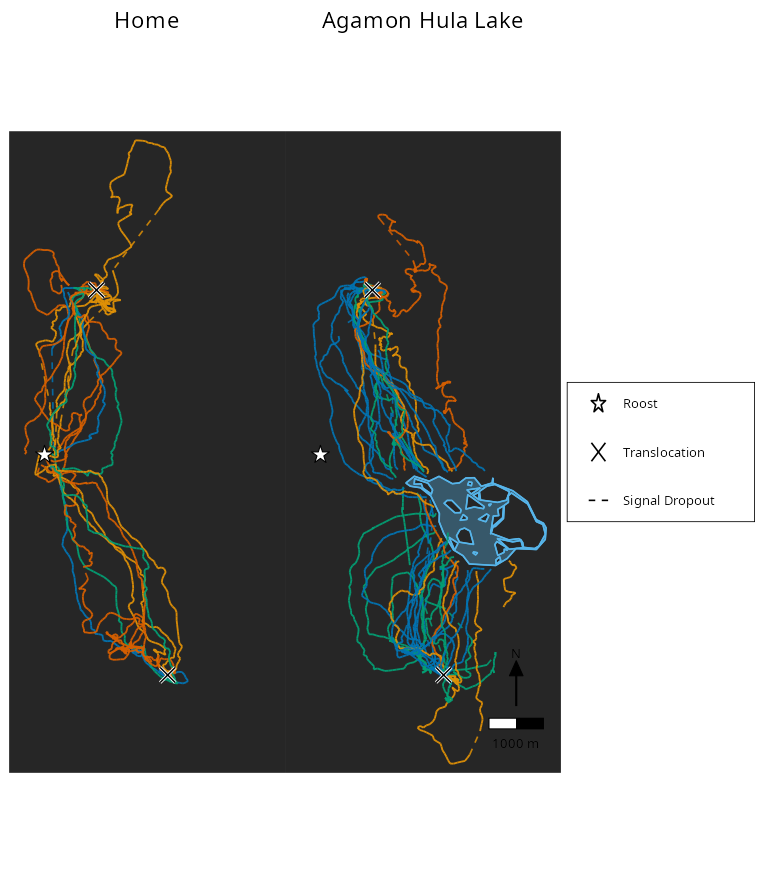

In [14]:
# Full-track destination panels by treatment x destination: one Home and
# one Agamon Hula Lake panel on dark CartoDB tiles (the Python twin
# requests zoom-15 retina tiles; z16 here at the same apparent
# resolution), no repeated treatment legend.
segs_treat <- segments_3857(track_w_treat)
site_bounds <- list(sf::st_bbox(lake_union_3857), sf::st_bbox(roost_3857),
  sf::st_bbox(trans_3857))
ext_dest <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.06)
bm_dark <- basemap_panel_img(ext_dest["xmin"], ext_dest["ymin"],
  ext_dest["xmax"], ext_dest["ymax"], "dark_all", 16, "#262626")
# The equal-aspect panel boxes of the 7x8 figure are ~0.43 wide/tall.
ae_dest <- aspect_extent(bm_dark, 0.43)
xlim_dest <- ae_dest$xlim; ylim_dest <- ae_dest$ylim
r_roost_dest <- marker_radius_m(220, 3.0, diff(xlim_dest))
r_trans_dest <- marker_radius_m(140, 3.0, diff(xlim_dest))
p_destination <- destination_panels(segs_treat, bm_dark, xlim_dest, ylim_dest, r_roost_dest, r_trans_dest)
save_figure(p_destination, "rediscretized_destination_panels", width = 7, height = 8)


The compact panels make the same routes easier to compare around each destination. The roost point and lake outline help distinguish a direct approach from travel across or away from the local goal direction.


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


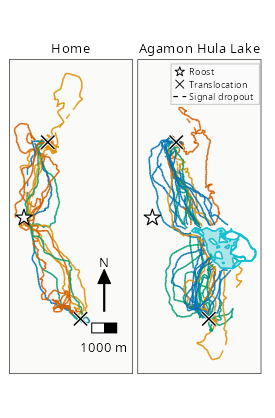

In [15]:
# Compact destination panels (one panel per destination) on light
# CartoDB Positron (no labels) tiles with black panel outlines and the
# legend inside the Agamon panel - the Python twin with fig_w=2.5,
# fig_h=3.8, title_fs=9, legend_fs=6.
ext_compact <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.05)
bm_light <- basemap_panel_img(ext_compact["xmin"], ext_compact["ymin"],
  ext_compact["xmax"], ext_compact["ymax"], "light_nolabels_novector", 15,
  "#fafaf8")
# The equal-aspect panel boxes of the 2.5x3.8 figure are ~1.22 x 3.10 in.
ae_compact <- aspect_extent(bm_light, 1.22 / 3.10)
xlim_c <- ae_compact$xlim; ylim_c <- ae_compact$ylim
r_roost_c <- marker_radius_m(150, 1.22, diff(xlim_c))
r_trans_c <- marker_radius_m(90, 1.22, diff(xlim_c))
p_destination_compact <- destination_panels_compact(segs_treat, bm_light, xlim_c, ylim_c, r_roost_c, r_trans_c)
save_figure(p_destination_compact, "rediscretized_destination_panels_compact",
  width = 2.5, height = 3.8)


The destination defines the reference for the bearing analysis. For lake-bound tracks, approaching an appropriate part of the shoreline should not be confused with missing a point target at the lake's center.


The original localization labels remain available as metadata. The fitted analysis uses the full usable bearings rather than restricting it to the labelled homing phase, allowing the mixture to represent the variation within each flight.


### The local direction toward the goal

The approach-direction plots show the reference against which each movement is measured. For a point goal, the arrows converge on the roost. Around the lake, they vary with position and follow the field toward the shoreline. This explains why the same compass heading can receive a different goal-relative bearing at different points along a flight.

A distribution centered near zero therefore indicates movement along these local approach directions. Its width tells us how consistently the bearings follow them. The distinction between this geometric reference and the fitted mean direction matters: the reference is supplied by the destination, while the mean is estimated from the bat's movements.


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


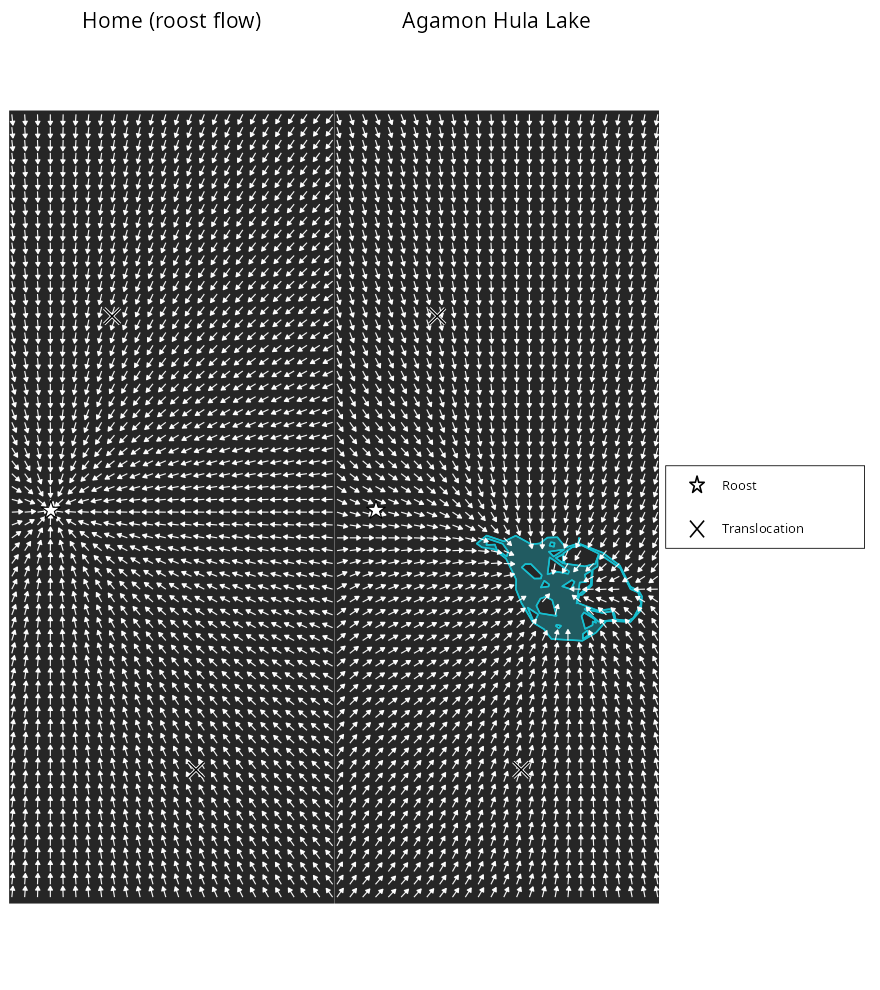

In [16]:
# Goal-approach direction fields feeding bearing_to_dest: the radial
# roost field over the Home panel and the smoothed-distance lake field
# over the Agamon Hula Lake panel, white quivers on dark CartoDB tiles
# (the Python twin uses lake_field="smoothed_distance", 200 m grids and
# no scale/compass UI).
ext_flow <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.06)
bm_flow <- basemap_panel_img(ext_flow["xmin"], ext_flow["ymin"],
  ext_flow["xmax"], ext_flow["ymax"], "dark_all", 15, "#262626")
# The equal-aspect panel boxes of the 8x9 figure are ~0.41 wide/tall.
ae_flow <- aspect_extent(bm_flow, 0.41)
xlim_flow <- ae_flow$xlim; ylim_flow <- ae_flow$ylim
r_roost_f <- marker_radius_m(220, 3.4, diff(xlim_flow))
r_trans_f <- marker_radius_m(140, 3.4, diff(xlim_flow))
p_flow <- flow_field_panels(bm_flow, xlim_flow, ylim_flow, r_roost_f, r_trans_f)
save_figure(p_flow, "destination_flow_fields_smoothed_distance", width = 8, height = 9)


### Describing the bearings before fitting a mixture

The circular density plots show whether bearings form a narrow peak near the goal direction, a broad spread, or a peak accompanied by substantial density elsewhere. A narrow central peak and a broad background are especially relevant here: they suggest that one measure of spread may be combining directed travel with more exploratory movement.

The initial summaries use each bat's complete set of bearings. **Mean resultant length**, $\bar R$, measures how closely the directions agree, approaching one for tightly clustered bearings and becoming small when directions cancel. The approximate von Mises concentration $\hat\kappa$ expresses overall concentration on the von Mises scale. At this stage, both summaries combine all kinds of movement in the flight.

**Alignment toward the goal** is the average cosine of the relative bearings,

$$
\widehat A_i=\frac{1}{n_i}\sum_{j=1}^{n_i}\cos\varepsilon_{ij}.
$$

It is positive for an overall tendency toward the goal and negative for a tendency away. Unlike concentration alone, it depends on where the distribution points as well as how tightly it is clustered. A bat can move consistently while following a direction displaced from the goal.

Each point represents one bat. The treatment summaries show medians and the 25th to 75th percentiles across bats, making the variation among individuals visible. These are descriptive ranges of individual responses; posterior uncertainty in treatment parameters appears later, after fitting the models.


In [17]:
descriptive_data <- track_w_treat[is.finite(track_w_treat$flightAngDiffDest_deg), ]
descriptive_data$HeadingRadians <- wrap(descriptive_data$flightAngDiffDest_deg * pi / 180)
descriptive_data$tag <- factor(descriptive_data$tag, levels = levels(df_track$tag))
descriptive_data$treatment <- factor(descriptive_data$treatment, levels = 1:4)
# Descriptive plots use all finite bearings, as in the source; their input
# need not exclude rows with missing along-field destination distances.
tag_observed <- split(descriptive_data, descriptive_data$tag)
kde_data <- do.call(rbind, lapply(tag_observed, function(g) {
  data.frame(theta = theta_grid, density = kde_vm(g$HeadingRadians, kappa = 15),
    tag = as.character(g$tag[1]), treatment = g$treatment[1])
}))
# Panel order in treatment blocks, tags ascending within each block; the
# same grouping the per-tag estimates below use for their colour.
tag_meta <- do.call(rbind, lapply(tag_observed, function(g) {
  data.frame(tag = as.character(g$tag[1]), treatment = g$treatment[1],
    stringsAsFactors = FALSE)
}))
tag_meta <- tag_meta[order(tag_meta$treatment, as.numeric(tag_meta$tag)), ]
p_polar_data <- polar_data_panels(kde_data, tag_meta)
descriptive <- do.call(rbind, lapply(tag_observed, function(g) {
  a <- g$HeadingRadians
  rbar <- resultant(a)
  data.frame(tag = as.character(g$tag[1]), treatment = g$treatment[1],
    n = length(a), Rbar = rbar, kappa_hat = estimate_kappa(rbar, length(a)),
    alignment0 = mean(cos(a)))
}))
treat_name_fmt <- vapply(tnames, fmt_treat_name, character(1))

p_kappa_desc <- desc_plot("kappa_hat", expression("Estimated " * hat(kappa)), c(0, 10), descriptive, treat_name_fmt, grid_y = TRUE)
p_R_desc <- desc_plot("Rbar", "Mean\nresultant length", c(-0.05, 1.05), descriptive, treat_name_fmt)
p_align_desc <- desc_plot("alignment0", "Alignment\nE[cos(y)]", c(0, 1.02), descriptive, treat_name_fmt)


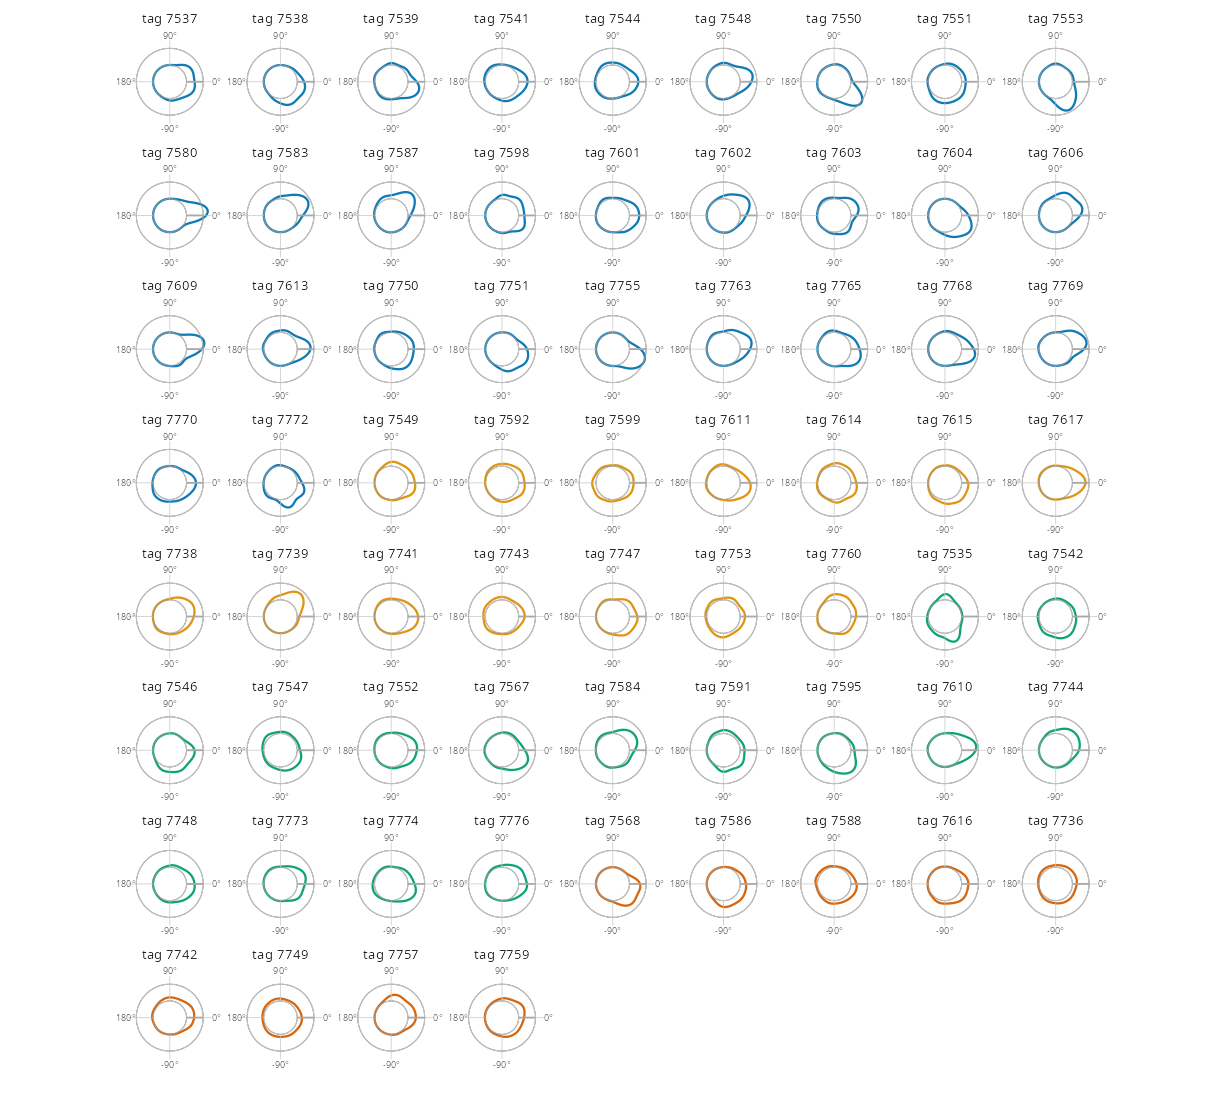

In [18]:
save_figure(p_polar_data, "polar_vonmises_kde_all", 11, 10)


This concentration summary describes each bat's full bearing distribution. Differences can reflect exploratory movement as well as precision during directed travel. The treatment intervals show the middle half of the individual values.


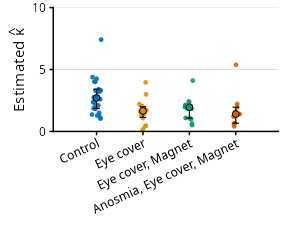

In [19]:
save_figure(p_kappa_desc, "kappa_hat_by_treatment_median_percentiles", 2.6, 2.2)


Mean resultant length shows how closely a bat's bearings agree, from dispersed or cancelling directions near zero to strong agreement near one. It provides an overall description before the mixture separates directed and undirected movement.


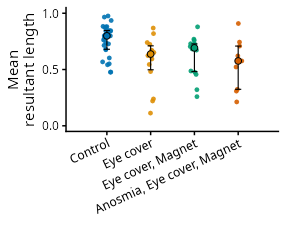

In [20]:
save_figure(p_R_desc, "rbar_by_treatment_median_percentiles", 2.6, 2.2)


Alignment adds the goal reference to that description. Bearings near the goal direction contribute positively, those across it contribute near zero, and those pointing away contribute negatively. Each point summarizes one bat's full usable track.


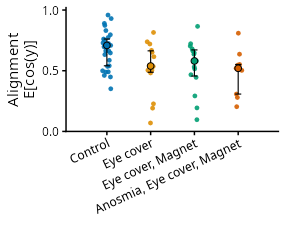

In [21]:
save_figure(p_align_desc, "alignment0_by_treatment_median_percentiles", 2.6, 2.2)


## A single von Mises model

We first describe each bat's bearings with one von Mises distribution. Its mean direction measures bias relative to the goal, and its concentration measures the spread of the full flight's bearings. Treatment effects allow both quantities to differ between experimental groups, while bat-specific effects allow individuals in a group to behave differently.

One concentration must account for both variation during directed travel and bearings collected during more exploratory movement. A lower fitted concentration cannot tell those explanations apart. Separating them is necessary to ask whether treatments affect precision during directed travel or the amount of directed movement within the flight.


For bearing $j$ from bat $i$ in treatment $t(i)$, the baseline is

$$
\varepsilon_{ij}\sim\mathcal M(\mu_i,\kappa_i),
$$

$$
\mu_i=\operatorname{wrap}\!\left(\beta_0+\beta_{t(i)}+b_i\right),
\qquad
\kappa_i=\operatorname{softplus}\!\left(\alpha_0+\alpha_{t(i)}+a_i\right).
$$

Here $\mathcal M$ denotes a von Mises distribution, and control is the reference treatment, whose treatment contrasts are set to zero. The terms $b_i$ and $a_i$ allow a bat's directional bias and concentration to depart from its treatment's shared pattern. Partial pooling helps estimate those departures without treating every short track as equally informative as a long one.

The circular link wraps mean directions back onto the circle. The softplus function, $\operatorname{softplus}(x)=\log(1+e^x)$, converts the concentration predictor to a positive value. Concentration effects are therefore additive on the predictor scale; they are not changes of the same numerical size in $\kappa$ itself. We return to bearings and predictive densities when interpreting their biological consequences.


In [22]:
# Python c41 uses Normal tag direction effects with a HalfNormal
# sd = 1/sqrt(30), not a von Mises tag prior. Preserve that actual model.
vector_vm <- stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }
", block = "functions")
base_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + tagshift),
  beta0 ~ 0 + Intercept + treat2 + treat3 + treat4,
  tagshift ~ 0 + (1 | tag),
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_von_mises)
base_priors <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds; a
  # uniform prior is NOT used (bounded uniform boxes pin NUTS chains
  # against the +-pi walls). Each coefficient's prior is its von Mises
  # log density, added as an explicit target term.
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_beta0[2:4] | 0, 2)", check = FALSE) +
  prior("normal(0, 0.18257418583505536)", class = "sd", nlpar = "tagshift") +
  prior("normal(log(exp(3) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: exact c41 values govern the baseline; the centered
# von Mises coefficient-vector pattern is needed for fixed direction
# effects, while tag shifts remain non-centered Gaussian effects here.
base_stanvars <- stan_unwrap_fun + modulo_circular_fun + vector_vm
base_stan <- make_stancode(base_form, data = df_track, prior = base_priors,
                           stanvars = base_stanvars)
stopifnot(grepl("vector[K_beta0] b_beta0;", base_stan, fixed = TRUE),
          !grepl("uniform_lpdf", base_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf", base_stan, fixed = TRUE))
cat(base_stan)
# Check the generated parameters block and coefficient order before init:
# b_beta0 has four unbounded entries: Intercept, treat2, treat3, treat4.
base_standata <- make_standata(base_form, data = df_track, prior = base_priors,
                              stanvars = base_stanvars)
base_parameter_block <- regmatches(base_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", base_stan, perl = TRUE))
base_parameter_block <- gsub("[[:space:]]", "", base_parameter_block)
stopifnot(length(base_parameter_block) == 1L,
  # Unbounded circular coefficient vector: plain real vector (the
  # Python circ_mod geometry), no +-pi bounds or uniform factors.
  grepl("vector[K_beta0]b_beta0;", base_parameter_block, fixed = TRUE),
  base_standata$K_beta0 == 4L,
  identical(colnames(base_standata$X_beta0),
    c("Intercept", "treat2", "treat3", "treat4")))

# Unbounded angular coefficients carry 2*pi-equivalent posterior wrap
# classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize only b_beta0 here; Gaussian tagshift
# effects and all kappa parameters retain CmdStan defaults.
base_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu_anchor <- as.numeric(base_treat_mean[levels(df_track$treatment)[1]])
treat_anchor <- as.numeric(mod_circular(
  base_treat_mean[levels(df_track$treatment)[-1]] - mu_anchor))
stopifnot(length(base_treat_mean) == nlevels(df_track$treatment),
  length(treat_anchor) == 3L,
  length(c(mu_anchor, treat_anchor)) == base_standata$K_beta0,
  abs(mu_anchor) < pi - 0.2, all(abs(treat_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_beta0 = as.numeric(c(mu_anchor, treat_anchor) + j(base_standata$K_beta0)))
}
set.seed(123)
fit_vm <- unwrap_load_fit_cache("bats_fit_vm_v2", SEED, ITER, WARMUP)
if (is.null(fit_vm)) {
  fit_vm <- brm(base_form, data = df_track, prior = base_priors,
    stanvars = base_stanvars, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED,
    init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
    control = list(adapt_delta = 0.97))
  unwrap_save_fit_cache("bats_fit_vm_v2", fit_vm, SEED, ITER, WARMUP)
}
base_parameters <- posterior::variables(posterior::as_draws_array(fit_vm))
base_angular <- base_parameters[grepl("^b_beta0_", base_parameters)]
base_summary <- diagnose_fit(fit_vm, angular = base_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

}
data {
  int<lower=1> N;  // 

Loading required namespace: rstan



Unwrap fit cache: reusing 'bats_fit_vm_v2' (seed 123, iter 4000, warmup 2000).



Divergences: not retained in this fit object (see R-hat/ESS below).
                          parameter         mean         sd      rhat  ess_bulk
1                 b_beta0_Intercept -0.067652484 0.08161690 1.0004684  1054.691
2                    b_beta0_treat2  0.154334475 0.14955954 1.0025994  1251.533
3                    b_beta0_treat3 -0.149886478 0.14057426 1.0008253  1538.951
4                    b_beta0_treat4 -0.077015969 0.16681322 1.0007359  1856.693
5                 b_kappa_Intercept  2.614964020 0.24727535 1.0022366  1681.258
6                    b_kappa_treat2 -1.213034556 0.42024535 1.0002858  1785.058
7                    b_kappa_treat3 -0.937985371 0.41211589 1.0006976  1601.960
8                    b_kappa_treat4 -1.167996380 0.48041491 1.0007572  1713.975
9           sd_tag__kappa_Intercept  1.383892853 0.15829504 1.0005732  2001.756
10       sd_tag__tagshift_Intercept  0.444117788 0.04066802 1.0000721  2016.655
11     r_tag__kappa[7535,Intercept] -1.787772724 0.5

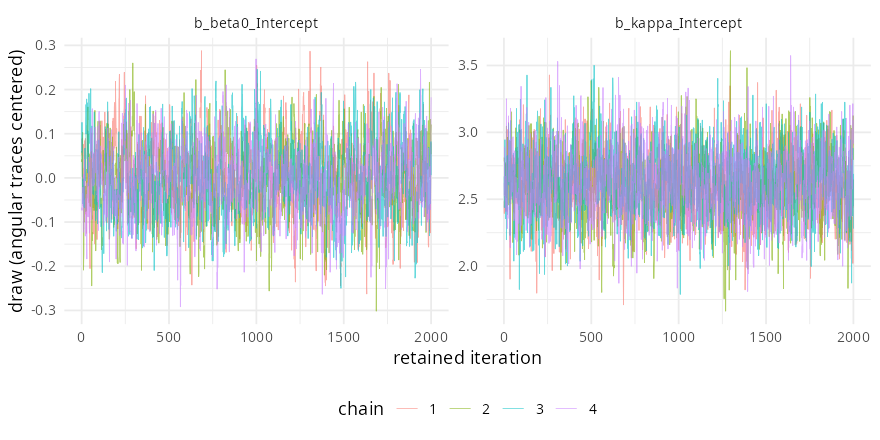

In [23]:
save_figure(trace_plot(fit_vm, c("b_beta0_Intercept", "b_kappa_Intercept"), base_angular), "vonmises_trace", 8, 4)


### Separating exploration from precision during directed travel

To separate these two sources of variation, we add a uniform component alongside the concentrated distribution of goal-relative bearings. The von Mises component can then describe the direction and precision of directed travel, while the uniform component accommodates effectively undirected exploration. The mixture estimates how much each contributes within a flight.

The mixture weight $\omega$ controls the share of bearings generated by the directed component. Because it is a proportion, it must remain between zero and one. The inverse-logit transformation enforces that constraint while allowing treatment and individual effects on the underlying predictor. The illustration below shows how uncertainty on that scale becomes uncertainty in a probability. It is a demonstration of the transformation, centered at 0.9; the fitted model's weight-intercept prior is centered at $\operatorname{logit}(0.8)$ on the predictor scale.


In [24]:
qs <- c(0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
data.frame(quantile = qs, probability = plogis(qnorm(qs, qlogis(0.9), 1)))


quantile,probability
<dbl>,<dbl>
0.01,0.4677640
0.05,0.6346855
0.10,0.7141596
0.25,0.8209408
0.50,0.9000000
0.75,0.9464303
0.90,0.9700778
0.95,0.9790014
0.99,0.9892663


### The von Mises–uniform mixture

The mixture density for bat $i$ is

$$
f_i(\varepsilon)=\omega_i\,\mathcal M(\varepsilon\mid\mu_i,\kappa_i)
+(1-\omega_i)\frac{1}{2\pi}.
$$

The von Mises component describes directed travel and the uniform component describes effectively undirected exploration. Their parameters have distinct roles. The mean $\mu_i$ measures directional bias relative to the goal, concentration $\kappa_i$ measures **directional precision** within directed travel, and the weight $\omega_i$ measures **goal-directedness**, the modeled share of directed bearings. The code names this weight `p`.

A high directed share can coexist with low precision, and precise directed travel can coexist with substantial exploration. The mean is also estimated rather than fixed at zero, so systematic bias remains visible. These components are inferred descriptions of movement from bearings, rather than behavioral labels supplied independently for each observation.

Treatment and bat effects enter all three parameters:

$$
\mu_i=\operatorname{wrap}\!\left(\beta_0+\beta_{t(i)}+b_i\right),
$$

$$
\kappa_i=\operatorname{softplus}\!\left(\alpha_0+\alpha_{t(i)}+a_i\right),
\qquad
\omega_i=\operatorname{logit}^{-1}\!\left(\gamma_0+\gamma_{t(i)}+c_i\right).
$$

The angular deviations $b_i$ have a von Mises distribution centered on zero. Their pooling concentration describes how much preferred directions vary **between bats**, while $\kappa_i$ describes precision **within a bat's directed movement**. The concentration and weight deviations use centered Gaussian distributions on their respective predictor scales. This hierarchy allows bats exposed to the same treatment to differ in all three aspects of navigation.

The baseline and mixture also use different concentration and angular-pooling priors. Their predictive comparison therefore concerns the fitted specifications as a whole. Both retain the same full set of usable bearings, so differences in their interpretation do not arise from selecting different homing segments.


In [25]:
# Cell 53's exact uniform-circle component; no near-uniform approximation
# enters the likelihood. brms generates target += unwrap_vmu_lpdf(...).
unwrap_vmu <- custom_family("unwrap_vmu", dpars = c("mu", "kappa", "pgoal"),
  links = c("identity", "softplus", "logit"),
  lb = c(NA, 0, 0), ub = c(NA, NA, 1), type = "real")
mixture_functions <- stanvar(scode = "
  real unwrap_vmu_lpdf(real y, real mu, real kappa, real pgoal) {
    return log_mix(pgoal, unwrap_von_mises_lpdf(y | mu, kappa), -log(2*pi()));
  }
  real unwrap_vmu_rng(real mu, real kappa, real pgoal) {
    if (bernoulli_rng(pgoal)) return unwrap_von_mises_rng(mu, kappa);
    return uniform_rng(-pi(), pi());
  }
", block = "functions")
mixture_hyper <- stanvar(scode = "real<lower=0> kmu_tag;", block = "parameters")
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
mix_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ mu0 + mutreat + mutag),
  mu0 ~ 1,
  mutreat ~ 0 + treat2 + treat3 + treat4,
  mutag ~ 0 + tag,
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  pgoal ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_vmu)
mix_priors <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds; a
  # uniform prior is NOT used (bounded uniform boxes pin NUTS chains
  # against the +-pi walls). Each coefficient's prior is its von Mises
  # log density, added as an explicit target term.
  set_prior("target += unwrap_von_mises_lpdf(b_mu0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutreat | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutag | 0, kmu_tag)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_tag | log(30), 0.1)", check = FALSE) +
  prior("normal(log(exp(5) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa") +
  prior("normal(log(0.8 / 0.2), 1)", class = "b", coef = "Intercept", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "pgoal") +
  prior("normal(0, 1)", class = "sd", dpar = "pgoal")
)
# PyMC's sigmoid([eta,-eta]) is (plogis(eta),1-plogis(eta)), not a
# two-logit softmax. The pgoal formula therefore uses eta, not 2*eta.
# (The uniform factor in the likelihood is the EXACT circular-uniform
# mixture component -log(2*pi), not a prior.)
mix_stanvars <- base_stanvars + mixture_functions + mixture_hyper
mix_stan <- make_stancode(mix_form, data = df_track, prior = mix_priors,
                          stanvars = mix_stanvars)
stopifnot(grepl("log_mix(pgoal", mix_stan, fixed = TRUE),
          grepl("kmu_tag", mix_stan, fixed = TRUE),
          grepl("target += unwrap_vmu_lpdf", mix_stan, fixed = TRUE))
cat(mix_stan)
# Check the generated parameters block and coefficient order before init:
# b_mu0: Intercept (1); b_mutreat: treat2, treat3, treat4 (3);
# b_mutag: one entry per tag, in levels(df_track$tag) order.
mix_standata <- make_standata(mix_form, data = df_track, prior = mix_priors,
                             stanvars = mix_stanvars)
mix_parameter_block <- regmatches(mix_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", mix_stan, perl = TRUE))
mix_parameter_block <- gsub("[[:space:]]", "", mix_parameter_block)
stopifnot(length(mix_parameter_block) == 1L,
  # Unbounded circular coefficient vectors: plain real vectors (the
  # Python circ_mod geometry), no +-pi bounds or uniform factors.
  all(vapply(c("mu0", "mutreat", "mutag"), function(p) {
    grepl(paste0("vector[K_", p, "]b_", p, ";"), mix_parameter_block, fixed = TRUE)
  }, logical(1))),
  !grepl("uniform_lpdf", mix_stan, fixed = TRUE),
  grepl("real<lower=0>kmu_tag;", mix_parameter_block, fixed = TRUE),
  mix_standata$K_mu0 == 1L, mix_standata$K_mutreat == 3L,
  mix_standata$K_mutag == nlevels(df_track$tag),
  identical(colnames(mix_standata$X_mu0), "Intercept"),
  identical(colnames(mix_standata$X_mutreat), c("treat2", "treat3", "treat4")),
  isTRUE(all.equal(mix_standata$X_mutag,
    model.matrix(~ 0 + tag, data = df_track), check.attributes = FALSE)))

# Unbounded angular coefficients carry 2*pi-equivalent posterior wrap
# classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize b_mu0, b_mutreat, b_mutag, and kmu_tag
# (30, the middle of its LogNormal(log(30), 0.1) hyperprior). Gaussian random
# effects and all kappa/pgoal parameters retain CmdStan defaults.
mix_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu0_anchor <- as.numeric(mix_treat_mean[levels(df_track$treatment)[1]])
mutreat_anchor <- as.numeric(mod_circular(
  mix_treat_mean[levels(df_track$treatment)[-1]] - mu0_anchor))
tag_mean <- tapply(df_track$HeadingRadians, df_track$tag, circ_mean)
tag_treatment <- vapply(levels(df_track$tag), function(tag_id) {
  treatment <- unique(as.character(df_track$treatment[df_track$tag == tag_id]))
  stopifnot(length(treatment) == 1L)
  treatment
}, character(1))
mutag_anchor <- as.numeric(mod_circular(tag_mean[levels(df_track$tag)] -
  mu0_anchor - c(0, mutreat_anchor)[match(tag_treatment, levels(df_track$treatment))]))
stopifnot(length(mix_treat_mean) == nlevels(df_track$treatment),
  length(mu0_anchor) == mix_standata$K_mu0,
  length(mutreat_anchor) == mix_standata$K_mutreat,
  length(tag_mean) == nlevels(df_track$tag),
  length(mutag_anchor) == mix_standata$K_mutag,
  abs(mu0_anchor) < pi - 0.2,
  all(abs(mutreat_anchor) < pi - 0.5), all(abs(mutag_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_mu0 = as.numeric(mu0_anchor + j(1)),
    b_mutreat = as.numeric(mutreat_anchor + j(length(mutreat_anchor))),
    b_mutag = as.numeric(mutag_anchor + j(length(mutag_anchor))),
    kmu_tag = 30)
}
set.seed(123)
fit_mix <- unwrap_load_fit_cache("bats_fit_mix_v2", SEED, ITER, WARMUP)
if (is.null(fit_mix)) {
  fit_mix <- brm(mix_form, data = df_track, prior = mix_priors,
    stanvars = mix_stanvars, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED,
    init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
    control = list(adapt_delta = 0.97))
  unwrap_save_fit_cache("bats_fit_mix_v2", fit_mix, SEED, ITER, WARMUP)
}
mix_parameters <- posterior::variables(posterior::as_draws_array(fit_mix))
mix_angular <- mix_parameters[grepl("^b_(mu0|mutreat|mutag)_", mix_parameters)]
mix_summary <- diagnose_fit(fit_mix, angular = mix_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

  
  real unwrap_vmu_lpdf(real 

Unwrap fit cache: reusing 'bats_fit_mix_v2' (seed 123, iter 4000, warmup 2000).



Divergences: not retained in this fit object (see R-hat/ESS below).
                       parameter         mean         sd      rhat ess_bulk
1                b_mu0_Intercept -0.081911676 0.04862696 1.0026562 1008.880
2               b_mutreat_treat2  0.161845184 0.08801994 1.0010127 1457.131
3               b_mutreat_treat3 -0.167323347 0.08799704 1.0004618 1132.488
4               b_mutreat_treat4 -0.054813188 0.10280546 1.0003594 1577.522
5                b_mutag_tag7535 -0.886995271 0.11584031 0.9999565 2587.523
6                b_mutag_tag7537  0.015141585 0.11368994 1.0006985 4555.612
7                b_mutag_tag7538 -0.497718804 0.10567116 1.0004029 4190.269
8                b_mutag_tag7539 -0.158887952 0.10192738 1.0001523 3328.650
9                b_mutag_tag7541 -0.069656386 0.09006467 1.0018018 3035.624
10               b_mutag_tag7542 -0.503319555 0.13758572 1.0001932 4421.107
11               b_mutag_tag7544  0.095983524 0.10674348 1.0013331 3704.298
12               b_m

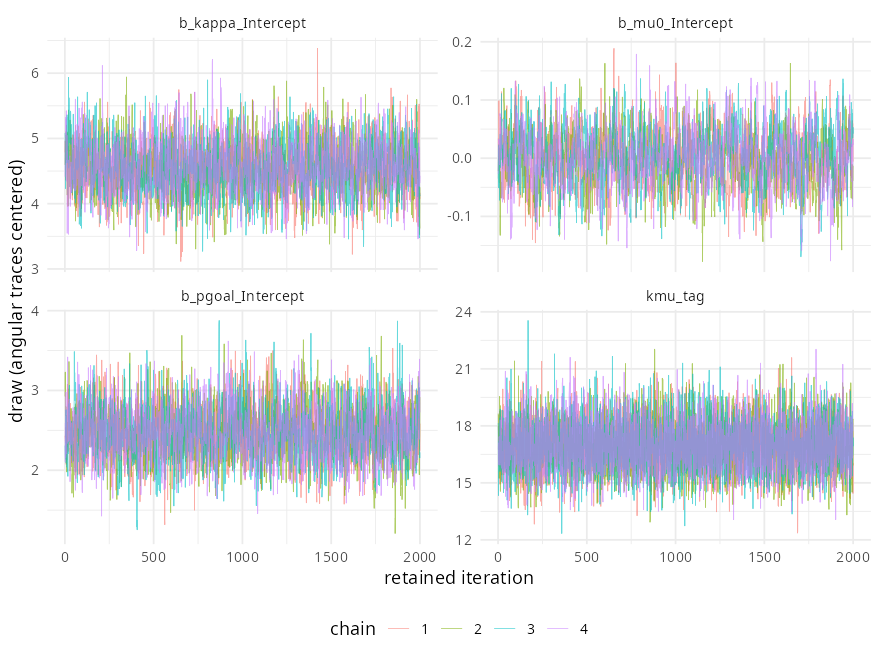

In [26]:
save_figure(trace_plot(fit_mix, c("b_mu0_Intercept", "b_kappa_Intercept", "b_pgoal_Intercept", "kmu_tag"), mix_angular), "mixture_trace", 8, 6)


### Sampling diagnostics

The saved R summaries show no flagged parameters, but the diagnostic helper flattens the draw and chain structure. Its R-hat and effective-sample-size calculations need to be repeated with chain identities preserved before they can establish between-chain convergence. Divergence information is also reported as unavailable. This qualification concerns the current diagnostic implementation and should remain separate from the biological interpretation of the model.

## Comparing predictions of individual bearings

To evaluate whether the extra component improves prediction, we use Pareto-smoothed importance-sampling leave-one-out cross-validation, or PSIS-LOO. Each bearing is evaluated as though it had been omitted from the fit, with the bat's other bearings still available. The comparison therefore asks which model better predicts another bearing from an observed bat. Predicting an entirely new bat would require withholding its observations together.

Expected log predictive density, or ELPD, adds these held-out predictive contributions across observations. A higher score means that the model assigns more predictive density to the omitted bearings. The Pareto-$k$ diagnostics assess the importance-sampling approximation; neither model has an observation with $k>0.7$ in the saved results.


In [27]:
population_grid <- data.frame(treatment = factor(1:4, levels = 1:4),
                              tag = factor(levels(df_track$tag)[1], levels = levels(df_track$tag)))
for (t in 2:4) population_grid[[paste0("treat", t)]] <- as.integer(population_grid$treatment == as.character(t))
set.seed(123)
PLOT_DRAWS <- if (quick_run) 200L else 2000L
plot_vm_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_vm)), PLOT_DRAWS)
plot_mix_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_mix)), PLOT_DRAWS)
pop_vm <- response_parameters(fit_vm, population_grid, population = TRUE, draw_ids = plot_vm_ids)
pop_mix <- response_parameters(fit_mix, population_grid, mixture = TRUE,
  population = TRUE, draw_ids = plot_mix_ids)
tag_grid <- df_track[!duplicated(df_track$tag), c("tag", "treatment", "treat2", "treat3", "treat4")]
tag_grid <- tag_grid[order(tag_grid$tag), ]
tag_mix <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = plot_mix_ids)


In [28]:
loo_vm <- explicit_loo(fit_vm)
loo_mix <- explicit_loo(fit_mix, mixture = TRUE)
loo_objects <- list("von Mises" = loo_vm, "von Mises-Uniform" = loo_mix)
res_total <- do.call(rbind, lapply(names(loo_objects), function(name) {
  x <- loo_objects[[name]]
  data.frame(model = name, elpd = x$estimates["elpd_loo", "Estimate"],
    se_elpd = x$estimates["elpd_loo", "SE"], pareto_k_max = max(x$diagnostics$pareto_k),
    pareto_n_gt_0.7 = sum(x$diagnostics$pareto_k > 0.7))
}))
res_total <- res_total[order(res_total$elpd, decreasing = TRUE), ]
print(res_total)
pointwise_delta <- loo_mix$pointwise[, "elpd_loo"] - loo_vm$pointwise[, "elpd_loo"]
delta_df <- rbind(delta_row(seq_len(nrow(df_track)), "Total"),
  do.call(rbind, lapply(levels(df_track$treatment), function(t) {
    delta_row(which(df_track$treatment == t), treatment_nice[[t]])
  })))
print(delta_df)
delta_individual <- do.call(rbind, lapply(split(seq_len(nrow(df_track)), df_track$tag), function(ii) {
  data.frame(tag = as.character(df_track$tag[ii[1]]), treatment = df_track$treatment[ii[1]],
    delta_row(ii, as.character(df_track$tag[ii[1]])))
}))
# Minimal black-and-white ELPD panels (Python twin look): best model on
# top, dashed line at the best total ELPD, no grid, bottom/left axes only.
p_total <- total_elpd_panel(res_total, FALSE, "ELPD")
delta_df$ypos <- seq(0L, 4L * 1.35, by = 1.35)  # Total row 0, treatments below
p_delta <- elpd_delta_plot(delta_df)
p_bracket <- elpd_bracket_plot(delta_df)
p_combined3 <- patchwork::wrap_plots(p_total, p_bracket, ncol = 1,
  heights = c(1.25, 1.35))
# Per-animal deltas, one colorblind panel per treatment (named).
tlabels_all <- levels(df_track$treatment)
p_delta_individual <- elpd_individual_plot(delta_individual)


              model      elpd  se_elpd pareto_k_max pareto_n_gt_0.7
2 von Mises-Uniform -6710.283 60.28762    0.4565785               0
1         von Mises -6829.407 59.29446    0.5429657               0


                       label    n delta_elpd se_delta_elpd
1                      Total 4942 119.123875     17.206374
2                    Control 1511  67.220196     12.840285
3                  Eye cover 1199  19.612736      7.024313
4          Eye cover, Magnet 1162  33.788584      8.496220
5 Anosmia, Eye cover, Magnet 1070  -1.497641      2.897504


In [29]:
pop_summary <- parameter_summary(pop_mix, population_grid)
tag_summary <- parameter_summary(tag_mix, tag_grid)
vm_summary <- parameter_summary(pop_vm, population_grid)
# Baseline coefficient panels: actual intercept/contrasts, not conditional
# response parameters. Angular intervals are centered on their circular mean.
base_draws <- as.data.frame(posterior::as_draws_df(fit_vm))
base_coef_names <- c("b_beta0_Intercept", paste0("b_beta0_treat", 2:4),
                      "b_kappa_Intercept", paste0("b_kappa_treat", 2:4))
base_coef <- do.call(rbind, lapply(base_coef_names, function(name) {
  angular <- grepl("b_beta0", name, fixed = TRUE)
  data.frame(parameter = name, component = if (angular) "mu (rad)" else "kappa (pre-softplus)",
    as.list(interval(base_draws[[name]], angular = angular)))
}))
coef_lab <- c("Control (Intercept)", treatment_nice[tlabels_all[-1]])
coef_pt <- do.call(rbind, lapply(seq_along(tlabels_all), function(i) {
  mn <- paste0("b_beta0_", c("Intercept", paste0("treat", 2:4))[i])
  kn <- paste0("b_kappa_", c("Intercept", paste0("treat", 2:4))[i])
  mid <- as.list(interval(base_draws[[mn]], angular = TRUE))
  kid <- as.list(interval(base_draws[[kn]]))
  rbind(data.frame(label = coef_lab[i], treatment = tlabels_all[i],
      comp = "mu", x = mid$mean, low = mid$low, high = mid$high, y = i - 0.16),
    data.frame(label = coef_lab[i], treatment = tlabels_all[i],
      comp = "kappa", x = kid$mean, low = kid$low, high = kid$high, y = i + 0.16))
}))
p_base_coef <- base_coef_plot(coef_pt, coef_lab)
vd <- vm_summary[vm_summary$quantity == "dens0_dir", ]
vd_lim <- range(c(min(vd$low, 1 / (2 * pi)), max(vd$high, 1 / (2 * pi))))
padvd <- 0.10 * diff(vd_lim)
p_base_density <- mean_hdi_plot(vm_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), vd_lim - c(padvd, -padvd))

theta <- seq(0, 2 * pi, length.out = 361)
polar_pdf <- do.call(rbind, lapply(seq_len(nrow(population_grid)), function(j) {
  do.call(rbind, lapply(theta, function(t) {
    pdf <- pop_mix$p[j, ] * exp(vm_logpdf(t, pop_mix$mu[j, ], pop_mix$kappa[j, ])) +
      (1 - pop_mix$p[j, ]) * exp(vm_logpdf(t, 0, KAPPA_UNIFORM))
    data.frame(treatment = population_grid$treatment[j], theta = t,
      median = median(pdf), as.list(hdi(pdf)))
  }))
}))
p_mixture_polar <- mixture_polar_plot(polar_pdf)
# Circular mean angle in degrees (interval in radians, scaled for display).
mudeg_pt <- do.call(rbind, lapply(seq_len(nrow(population_grid)), function(j) {
  md <- as.list(interval(pop_mix$mu[j, ], angular = TRUE))
  data.frame(treatment = population_grid$treatment[j], quantity = "mu_deg",
    mean = md$mean * 180 / pi, low = md$low * 180 / pi, high = md$high * 180 / pi)
}))
dens_xlim <- c(0, 1.05 * max(pop_summary$high[pop_summary$quantity == "dens0_dir"],
  vm_summary$high[vm_summary$quantity == "dens0_dir"]))
p_weight <- mean_hdi_plot(pop_summary, "p", "Mixture weight", 0.5, c(0, 1))
p_kappa <- mean_hdi_plot(pop_summary, "kappa", "Concentration (\u03ba)")
p_mix_density <- mean_hdi_plot(pop_summary, "dens0_mix",
  "Predictive density (mixture)", 1 / (2 * pi), dens_xlim)
p_dir_density <- mean_hdi_plot(pop_summary, "dens0_dir",
  "Predictive density (directed component)", 1 / (2 * pi), dens_xlim)
p_mass <- mean_hdi_plot(pop_summary, "mass45", "Predictive mass (\u00b145\u00b0)",
  0.25, c(0, 1))
p_align <- mean_hdi_plot(pop_summary, "align0", "Alignment", NULL, c(0, 1))
p_mu_deg <- mean_hdi_plot(mudeg_pt, "mu_deg", "Mean angle (deg)", 0)
p_mrl <- mean_hdi_plot(pop_summary, "mrl", "MRL (directed component)", 0, c(0, 1))
# The 2x2 twin places treatment rows control-on-bottom: flipped copies of
# the four quadrant plots (the standalone saves keep control-on-top).
p_mu_deg_f <- mean_hdi_plot(mudeg_pt, "mu_deg", "Mean angle (deg)", 0, flip = TRUE)
p_weight_f <- mean_hdi_plot(pop_summary, "p", "Mixture weight", 0.5, c(0, 1),
  flip = TRUE)
p_mrl_f <- mean_hdi_plot(pop_summary, "mrl", "MRL (directed component)", 0, c(0, 1),
  flip = TRUE)
p_dir_density_f <- mean_hdi_plot(pop_summary, "dens0_dir",
  "Predictive density", 1 / (2 * pi), dens_xlim, flip = TRUE)
# Matched vMU-vs-vM comparison: shared x limits over both summaries
# (including the uniform line) plus the 10% twin padding.
shm <- c(min(vd_lim[1], vd_lim[2],
    min(pop_summary$low[pop_summary$quantity == "dens0_dir"], 1 / (2 * pi))),
  max(vd_lim[2], max(pop_summary$high[pop_summary$quantity == "dens0_dir"],
    1 / (2 * pi))))
padshm <- 0.10 * diff(shm)
shm_lim <- shm - c(padshm, -padshm)
# 3-panel predictive limit: mixture summary + uniform line, 10% padding.
plim <- range(c(pop_summary$low[pop_summary$quantity == "dens0_mix"],
  pop_summary$high[pop_summary$quantity == "dens0_mix"], 1 / (2 * pi)))
padpl <- 0.10 * diff(plim)
plim <- plim - c(padpl, -padpl)


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”


The control row gives the reference parameters, and the other rows describe treatment contrasts. Direction effects shift the mean bearing relative to the goal; concentration effects change the predictor before softplus. The following density summaries translate these parameter changes back into a distribution of movement bearings.


`height` was translated to `width`.


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'μ' in 'mbcsToSbcs': for μ (U+03BC)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'κ' in 'mbcsToSbcs': for κ (U+03BA)”


`height` was translated to `width`.


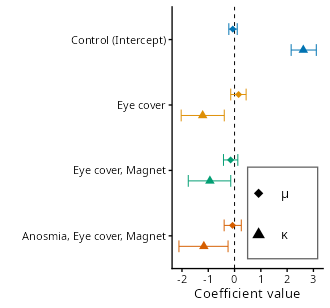

In [30]:
save_figure(p_base_coef, "treatment_coefficients_mu_kappa", 3.0, 2.8)


Density at zero measures how strongly the single-distribution model concentrates around the goal direction. It combines directional bias and concentration. The dashed reference, $1/(2\pi)$, is the density of uniform bearings; the plotted value is a density per radian, rather than a return-success probability.


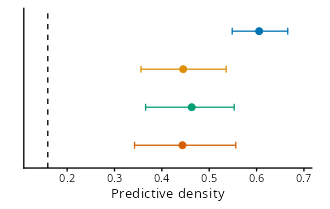

In [31]:
save_figure(p_base_density, "treatment_pred_density_at0_mu_kappa", 3.0, 1.9)


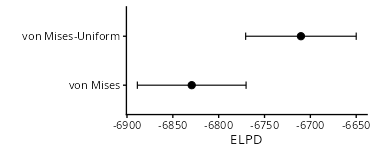

In [32]:
save_figure(p_total, "psisloo_total_elpd_all_models", 3.4, 1.4)


The plotted difference is

$$
\Delta\mathrm{ELPD}=\mathrm{ELPD}_{\mathrm{vMU}}-\mathrm{ELPD}_{\mathrm{vM}},
$$

so positive values favor the mixture. The R fit gives a total difference of **119.12**, with a conventional pointwise standard error of **17.21**. The mixture's additional flexibility substantially improves prediction overall, subject to the sampling-diagnostic qualification above.

The treatment breakdown shows that the gain is uneven. It is positive for control, eye cover, and eye cover plus magnet, while the eye cover plus magnet plus anosmia group shows little overall improvement. A predictive gain establishes that the likelihood describes those bearings better; it does not by itself establish a treatment effect on goal-directedness or precision. The individual scores locate where predictions improve; the fitted treatment parameters address differences in goal-directedness and precision.


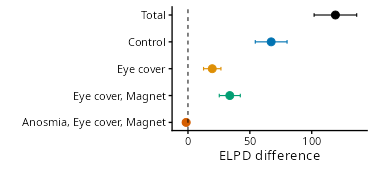

In [33]:
save_figure(p_delta, "psisloo_delta_total_and_by_treatment_vMU_minus_vM", 3.4, 1.55)


The total scores show the mixture's overall predictive advantage, while the treatment differences show where that gain occurs. Together they motivate examining individual flights and treatment parameters rather than interpreting better prediction as a uniform effect across all animals.


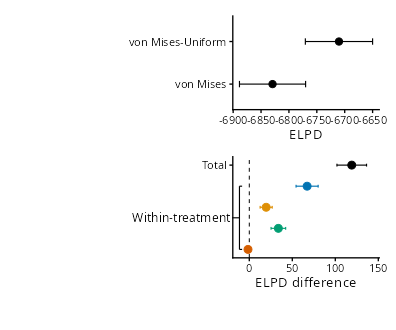

In [34]:
# Combined two-panel figure (Python twin look): total ELPD by model on
# top, the total delta point plus a "Within-treatment" bracket over the
# per-treatment deltas (colorblind) below.
save_figure(p_combined3, "psisloo_combined", 3.6, 3.0)


The individual panels reveal whether an overall gain is shared broadly or concentrated in particular bats. Here the advantage of the mixture is concentrated in a subset of individuals. This is consistent with variation in flight structure: a separate undirected component is more useful for some trajectories, while others are already described reasonably well by one von Mises distribution. Read the scores alongside the individual bearing distributions rather than assuming every flight requires the same decomposition.

Each bat's score sums its pointwise contributions, so bats with more bearings have more opportunity to influence the total. These panels help locate predictive improvement in the recorded sample; their treatment sums are not equal-weight averages of bat-level improvements.


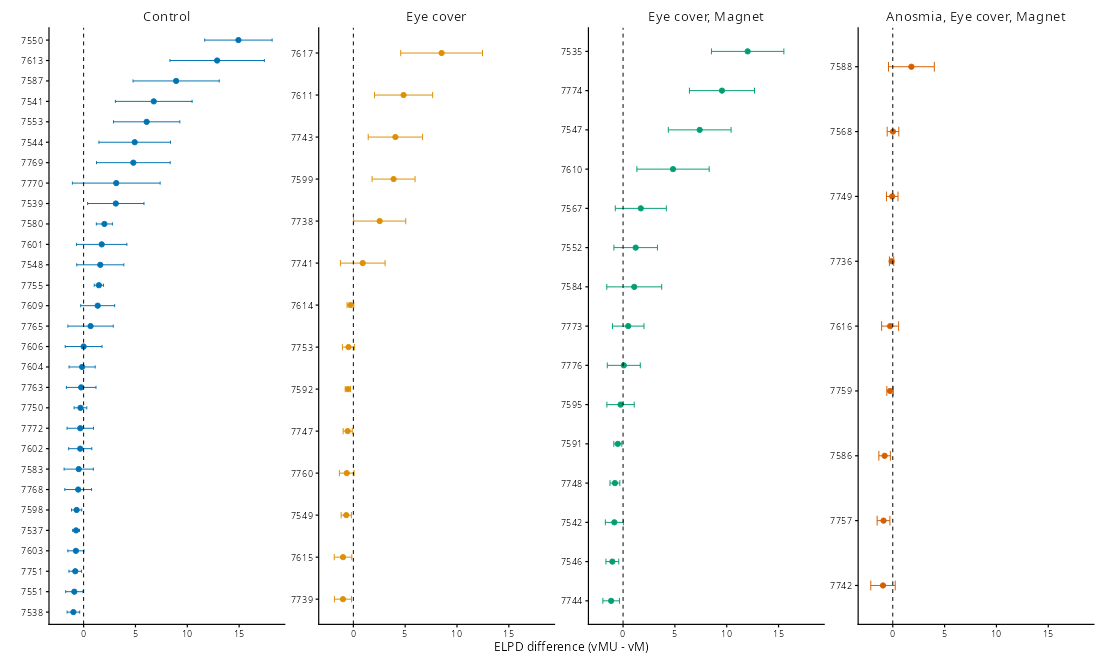

In [35]:
save_figure(p_delta_individual, "psisloo_delta_by_individual_by_treatment_vMU_minus_vM", 10, 6)


## Goal-directedness and precision across treatments

The treatment curves summarize the shared pattern for each experimental group, with the bat-specific deviations set to zero. This provides a common basis for comparing conditions; the individual plots that follow show how much bats depart from it.

All four fitted distributions retain a pronounced tendency toward the goal direction. The question is how that tendency changes under sensory deprivation. It can become less precise, shift away from the goal, or account for a different share of the flight's bearings. The mixture gives these changes separate parameters instead of forcing them all into one measure of spread.

The polar plots show the full mixture, including the undirected background. The 95% posterior intervals in the treatment summaries express uncertainty about the fitted quantities, whereas the earlier interquartile ranges described variation among the individual bats' summaries.


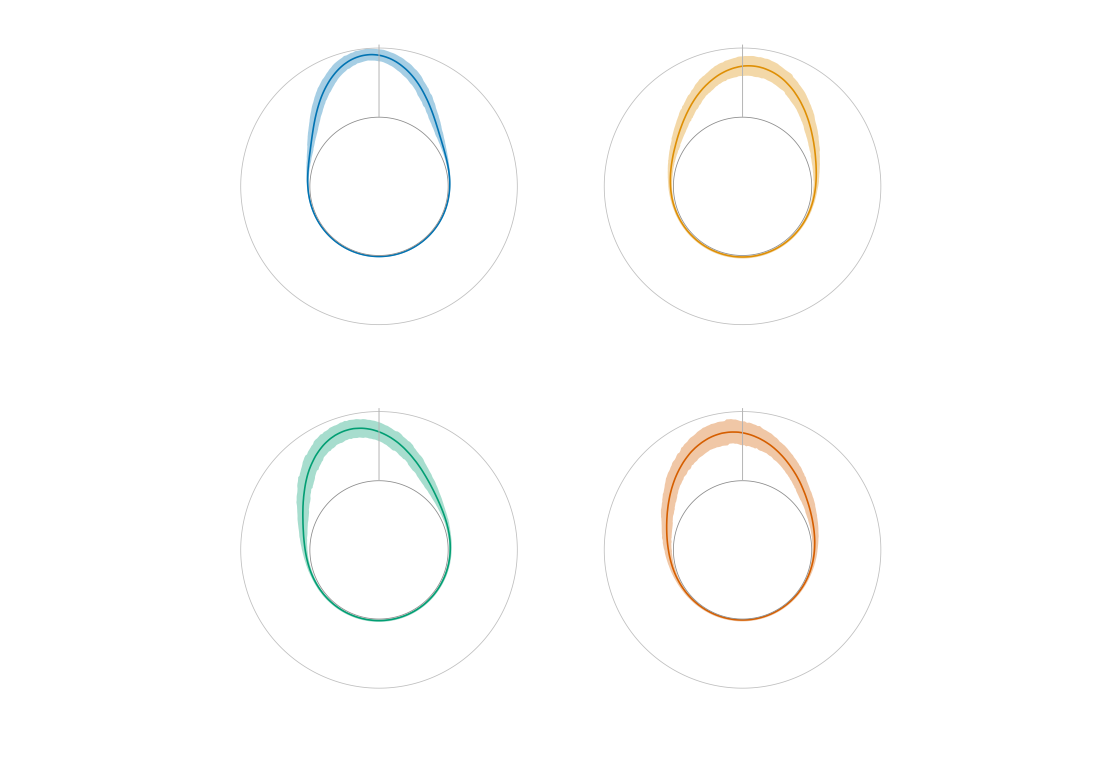

In [36]:
save_figure(p_mixture_polar, "vmum_mixture_full_polar_pdfs_population_only", 10, 7)


### Reading goal-directedness, precision, and alignment together

The weight $\omega$ answers how much of the sampled movement is described by the directed component. Its estimates are high in all four groups, approximately 0.88–0.94, with overlapping intervals. The dashed line at 0.5 marks equal weights for directed and undirected bearings. It does not represent a uniform heading distribution, because half of that mixture is still directed.

Concentration $\kappa$ describes how precisely the directed bearings follow their mean. The corresponding mean resultant length,

$$
A(\kappa)=\frac{I_1(\kappa)}{I_0(\kappa)},
$$

puts this precision on a scale from zero to one, from broad to tightly clustered bearings. Here $I_0$ and $I_1$ are modified Bessel functions. A high $\omega$ and a lower $A(\kappa)$ describe a bat that often travels directionally but does so less precisely.

To relate the fitted distribution directly to the destination, we also evaluate its **density at the goal direction**:

$$
f(0)=\omega\,\mathcal M(0\mid\mu,\kappa)+(1-\omega)/(2\pi).
$$

This combines directional bias, precision, and the share of directed bearings. The separate directed-component panel evaluates $\mathcal M(0\mid\mu,\kappa)$ alone, allowing us to examine travel within that component. Density is measured per radian; the uniform reference is $1/(2\pi)\approx0.159$.

The probability of traveling within $45^\circ$ of the goal direction answers a related question over a finite angular range:

$$
P(|\varepsilon|\le\pi/4)
=\omega\int_{-\pi/4}^{\pi/4}\mathcal M(u\mid\mu,\kappa)\,du+(1-\omega)/4.
$$

Its uniform reference is 0.25, because that sector covers one quarter of the circle. These density and sector summaries concern a movement bearing, rather than the probability of eventually returning home.

Finally, the full mixture's expected **alignment toward the goal** is

$$
E[\cos\varepsilon]=\omega\,A(\kappa)\cos\mu.
$$

The expression shows why goal-directedness, precision, and bias all matter. Even a high share of directed bearings gives modest overall alignment if those bearings are broad or consistently displaced from the goal. Reading the separate parameters alongside this combined measure makes the treatment comparison more informative.


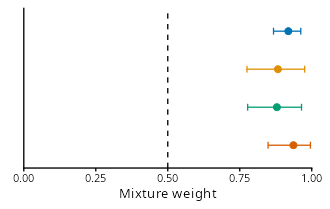

In [37]:
save_figure(p_weight, "fullmodel_mixture_weight_by_treatment_mean_hdi", 3.0, 1.9)


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Concentration (κ)' in 'mbcsToSbcs': for κ (U+03BA)”


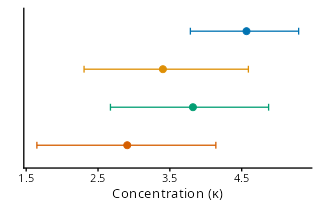

In [38]:
save_figure(p_kappa, "fullmodel_kappa_by_treatment_mean_hdi", 3.0, 1.9)


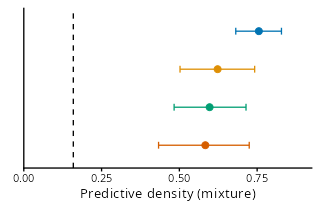

In [39]:
save_figure(p_mix_density, "fullmodel_predictive_density_at_0_mixture_by_treatment_mean_hdi", 3.0, 1.9)


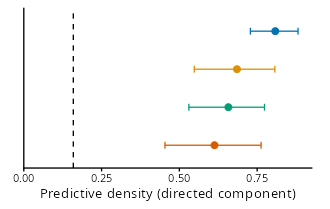

In [40]:
save_figure(p_dir_density, "fullmodel_predictive_density_at_0_directed_component_by_treatment_mean_hdi", 3.0, 1.9)


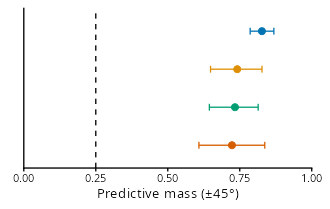

In [41]:
save_figure(p_mass, "fullmodel_predictive_mass_pm45deg_by_treatment_mean_hdi", 3.0, 1.9)


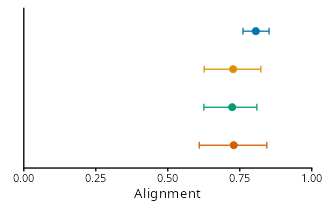

In [42]:
save_figure(p_align, "fullmodel_alignment_to_zero_by_treatment_mean_hdi", 3.0, 1.9)


The combined figure brings the predictive comparison together with the treatment estimates. The mixture captures the bearings better overall, while retaining a substantial directed component in every sensory condition. The control's directed component is the most concentrated in the displayed summaries, but the treatment estimates have appreciable uncertainty.

A high proportion of directed bearings can coexist with reduced precision during directed travel. Concentration now describes bearings assigned to directed travel, whereas the baseline uses it to describe the entire flight. In these fits, treatment differences are also estimated less precisely after that separation. The individual estimates are therefore needed to judge whether an apparent difference between group summaries reflects a consistent response across bats.

In this particular display, mean resultant length and density at zero refer to the directed component. They describe the precision and goal-relative orientation of directed travel, while the weight panel describes how much of the sampled movement is assigned to it.


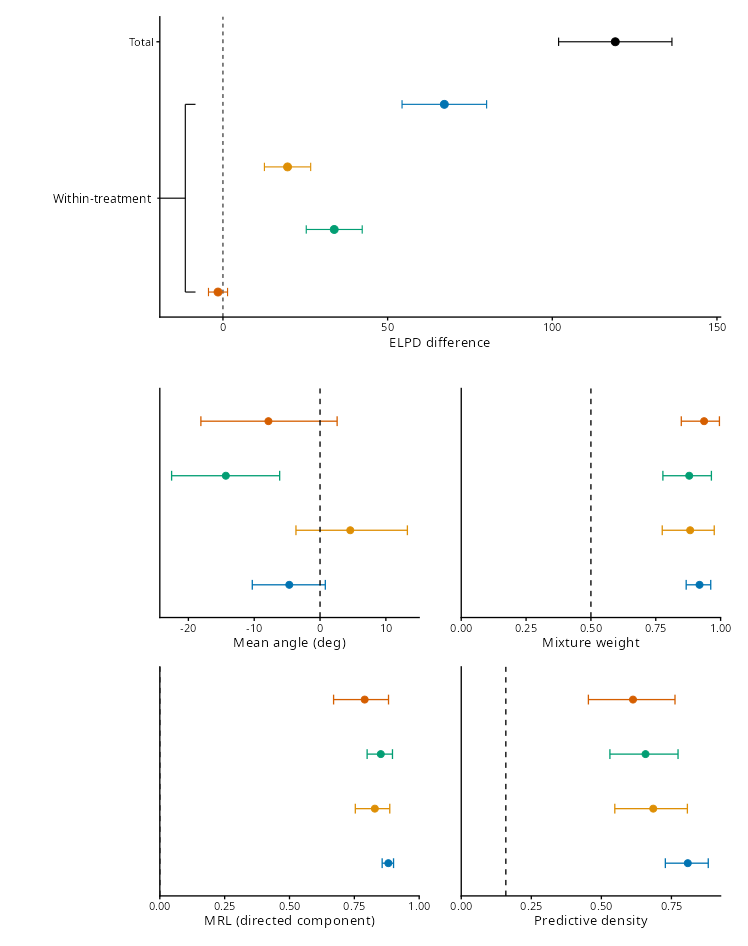

In [43]:
# Combined summary (Python twin): the delta-bracket panel on top with
# the population vMU parameters in a 2x2 block below (mean angle in
# degrees, mixture weight, MRL, directed-component predictive density);
# bottom panels hide the treatment labels so rows align across columns.
p_2x2 <- patchwork::wrap_plots(
  p_bracket,
  (p_mu_deg_f | p_weight_f) / (p_mrl_f | p_dir_density_f),
  ncol = 1)
p_2x2 <- p_2x2 + plot_layout(heights = c(1.45, 2.45))
save_figure(p_2x2, "psisloo_plus_params_2x2", 6.8, 8.6)


The matched density panels show the change in interpretation particularly clearly. In the single von Mises model, every bearing contributes to the same distribution, so exploratory movement broadens it. In the mixture, the directed component can remain sharper while the uniform component accommodates broadly scattered bearings.

In these fits, the directed-component density at the goal is higher after this separation, and uncertainty about treatment differences is substantially wider. The plotted estimates can still suggest differences between conditions, but the range of plausible effects is larger. This is why an apparent loss of concentration in the whole flight should not automatically be interpreted as a loss of precision during homing.

The upper comparison uses the mixture's directed component alone, rather than its full density. The same distinction should be kept in view when comparing it with the single-distribution baseline.


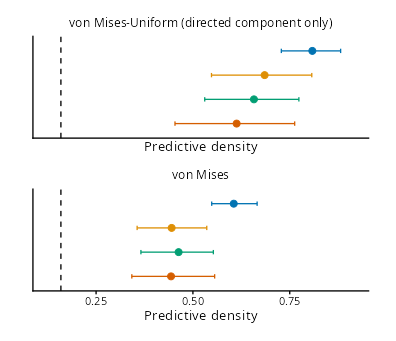

In [44]:
# Matched two-panel comparison (Python twin): the vMU model's
# directed-component-only predictive density at the goal (top) vs the
# von Mises baseline (bottom); shared x limits, hidden treatment labels,
# dashed uniform-density reference.
p_vmu_dens <- mean_hdi_plot(pop_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), shm_lim) +
  labs(title = "von Mises-Uniform (directed component only)") +
  theme(plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_blank(), axis.ticks.x = element_blank())
p_vm_dens <- mean_hdi_plot(vm_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), shm_lim) +
  labs(title = "von Mises") +
  theme(plot.title = element_text(size = 8, hjust = 0.5))
save_figure(patchwork::wrap_plots(p_vmu_dens, p_vm_dens, ncol = 1),
  "predictive_density_two_model_comparison_matched_vmu_directed_vs_vm",
  3.6, 3.1)


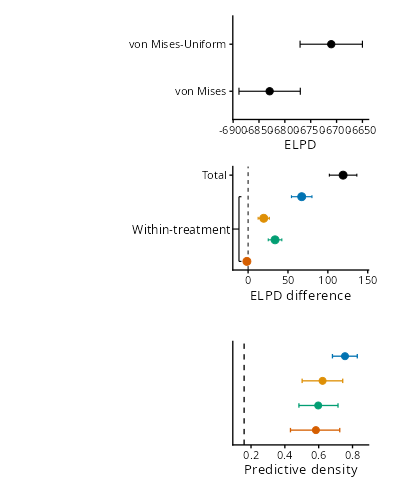

In [45]:
# Three-panel summary (Python twin): total ELPD by model, the delta
# ELPD bracket panel, and the vMU mixture predictive density at the goal
# (hidden treatment labels, dashed uniform reference).
p_p3 <- mean_hdi_plot(pop_summary, "dens0_mix", "Predictive density",
  1 / (2 * pi), plim)
p_3panel <- patchwork::wrap_plots(p_total, p_bracket, p_p3, ncol = 1)
save_figure(p_3panel, "psisloo_plus_predictive_density_3panel", 3.6, 4.5)


## Variation between individual bats

Bats in the same sensory condition differ considerably in goal-directedness and directional precision. Some have a high directed share and tightly clustered goal-relative bearings; others combine directed travel with more diffuse movement or show broader bearings within the directed component. The individual panels make those combinations visible.

This variation is central to the treatment interpretation. A change in a group summary does not mean that the same change appears consistently across its bats. The pronounced between-individual differences help explain why treatment contrasts remain uncertain after exploratory movement is represented explicitly.

The gray bands show posterior uncertainty in the shared treatment quantities. They are not ranges designed to contain a fixed proportion of animals. The individual intervals describe uncertainty about each bat, which depends in part on how much information its track supplies. Read both the differences among bats and the uncertainty of their estimates before drawing a treatment-wide conclusion.


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


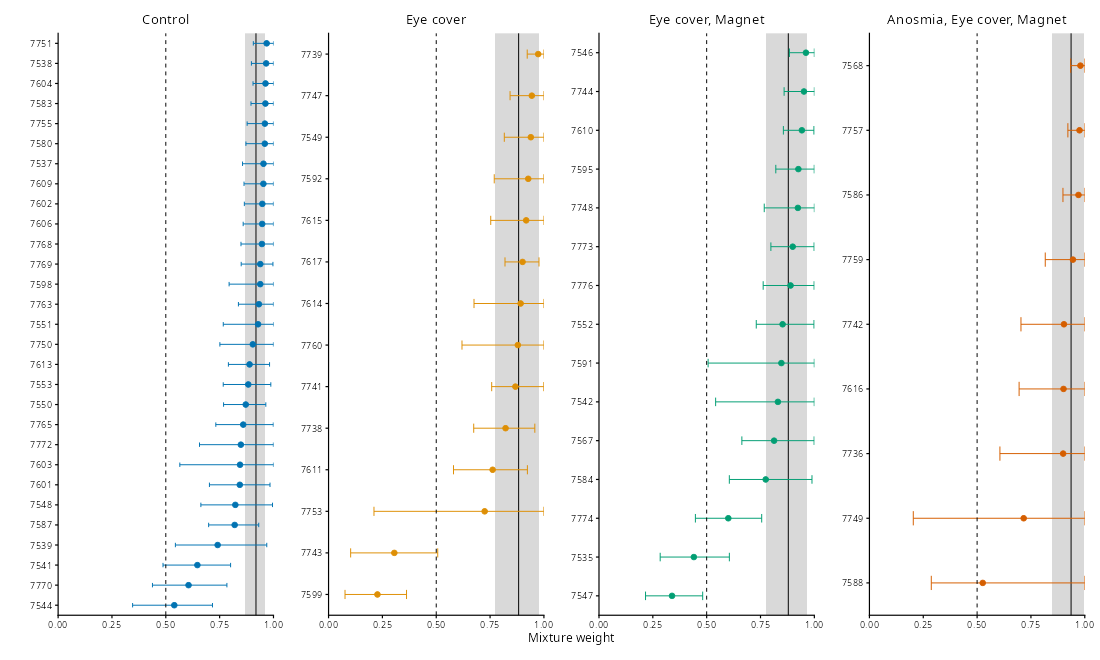

In [46]:
save_figure(tag_hdi_plot("p", "Mixture weight", 0.5, xlimits = c(0, 1)), "fullmodel_taglevel_mixture_weight_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


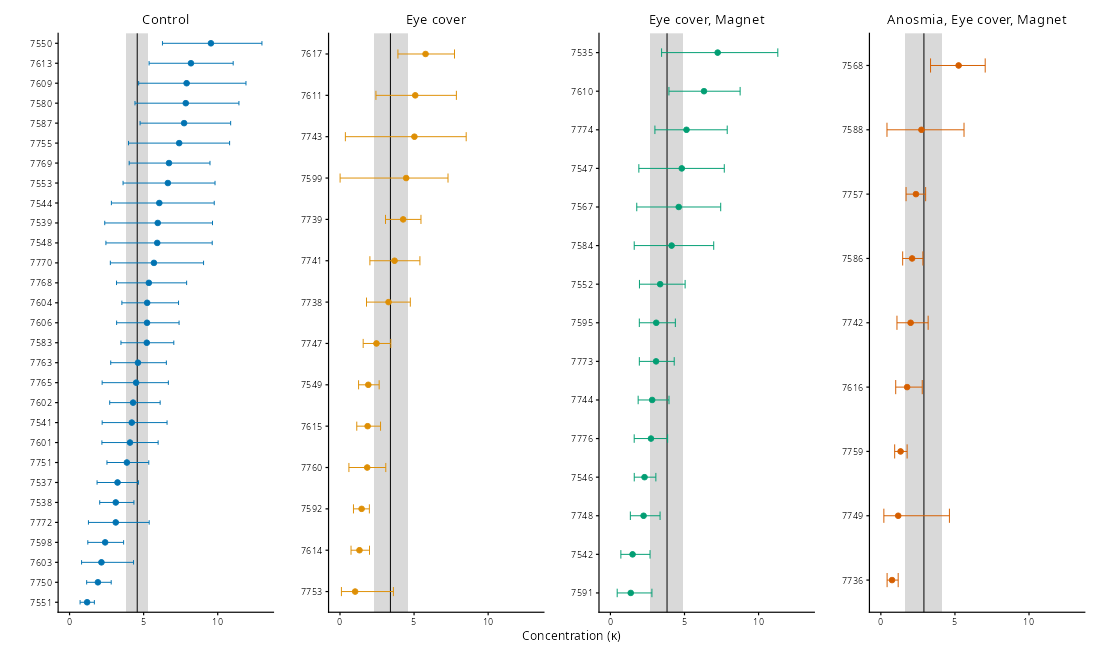

In [47]:
save_figure(tag_hdi_plot("kappa", expression("Concentration (" * kappa * ")")), "fullmodel_taglevel_kappa_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


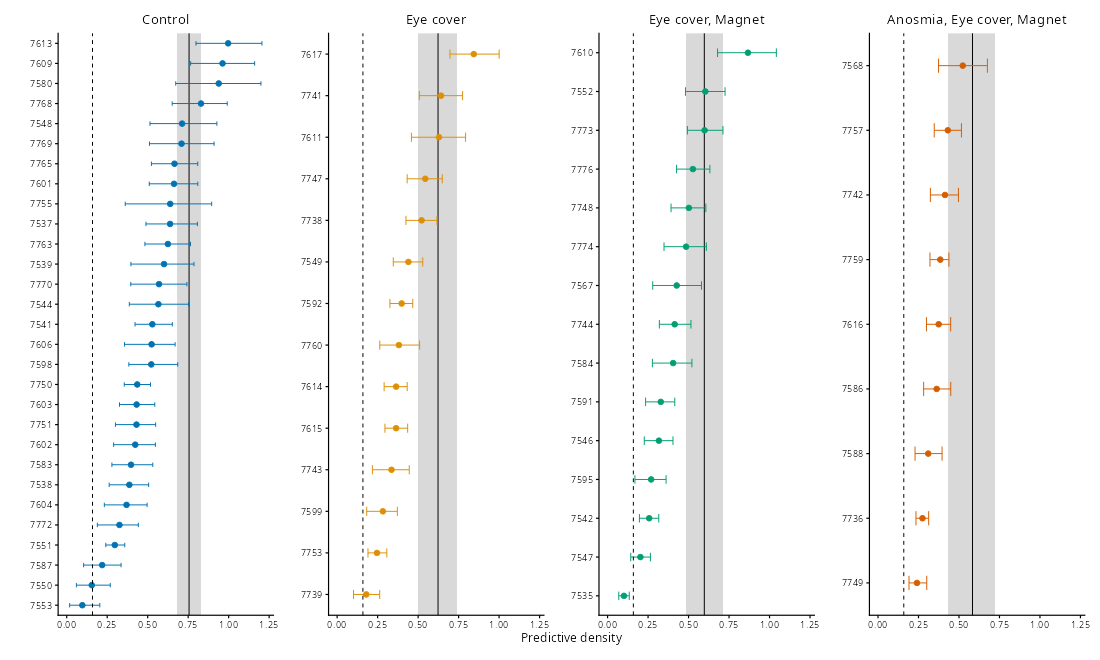

In [48]:
save_figure(tag_hdi_plot("dens0_mix", "Predictive density", 1 / (2 * pi)), "fullmodel_taglevel_predictive_density_at_0_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


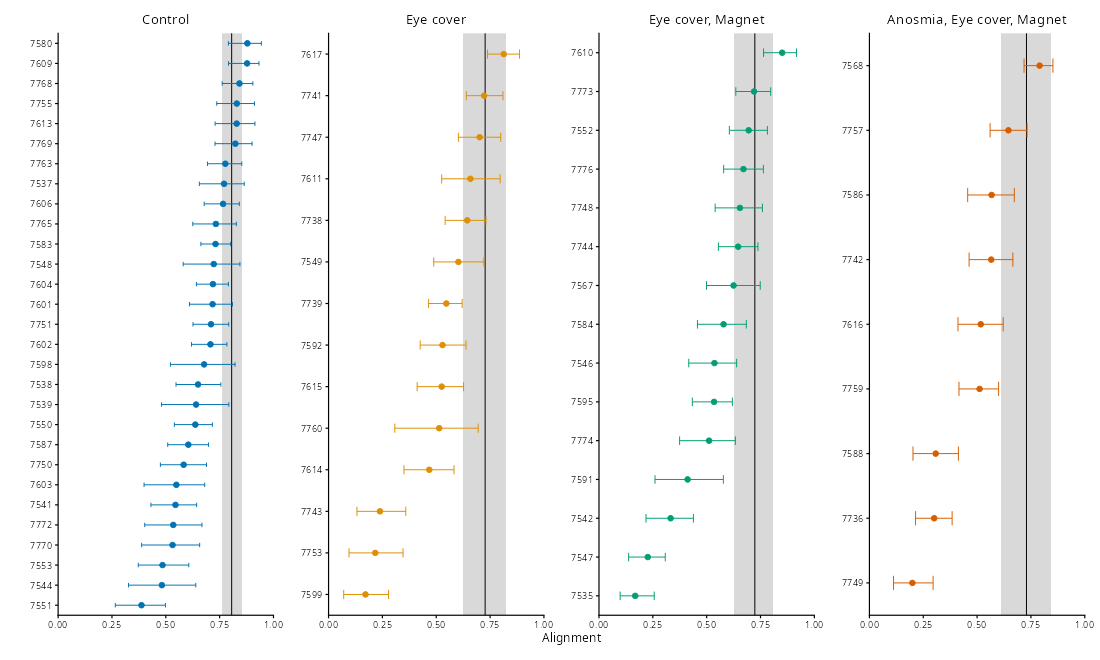

In [49]:
save_figure(tag_hdi_plot("align0", "Alignment", xlimits = c(0, 1)), "fullmodel_taglevel_alignment_to_zero_by_treatment_mean_hdi", 10, 6)


## Checking the distributions predicted by the mixture

The behavioral interpretation depends on how well the mixture describes the observations. The predictive checks ask whether it could generate bearing distributions with the same main peak, width, and background as those recorded.

For each replicate, we simulate bearings using the fitted parameters of the observed bats and retain each bat's observed sample size. A bearing is generated from either its directed von Mises component or the uniform component according to its mixture weight. We summarize the simulated bearings with the same circular density estimates used for the observations.

At the treatment level, the resampling procedure selects bats and then bearings within them, pooling the selected bearings before estimating a density. Longer recordings therefore contribute more observations to this particular comparison. The observed bootstrap and simulated datasets use corresponding summaries, so the check compares like with like.

The fitted mixture broadly reproduces the concentration near the goal and the surrounding spread in the saved panels. Compare peak location, width, and tails to see where it succeeds or misses structure. The bands describe uncertainty in these density estimates, including variation in simulated datasets; the check concerns the distribution of bearings and does not preserve the temporal sequence of turns.


In [50]:
# Full budgets reproduce the source's local bootstrap/draw budgets.
N_WORKERS <- min(8L, max(2L, parallel::detectCores()))
# The per-treatment and per-tag blocks below are independent and run
# forked in parallel: per-task results are reproducible (per-tag
# tasks set their own seed; per-treatment tasks inherit one common
# stream state).
N_BOOT_OBS <- if (quick_run) 150L else 1000L
N_PPC_DRAWS <- if (quick_run) 150L else 4000L
N_INDIV_BOOT <- if (quick_run) 100L else 500L
N_INDIV_DRAWS <- if (quick_run) 100L else 500L
THETA_N <- 360L
angles <- seq(0, 2 * pi, length.out = THETA_N + 1L)[-(THETA_N + 1L)]
bins <- seq(-pi, pi, length.out = 17)
bin_centers <- (head(bins, -1) + tail(bins, -1)) / 2
set.seed(123)
nd <- posterior::ndraws(posterior::as_draws_array(fit_mix))
ppc_ids <- sample.int(nd, min(nd, max(N_PPC_DRAWS, N_INDIV_DRAWS)))
ppc_par <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = ppc_ids)
tag_rows <- split(seq_len(nrow(df_track)), df_track$tag)
stopifnot(identical(names(tag_rows), as.character(tag_grid$tag)))
population_ppc <- do.call(rbind, parallel::mclapply(levels(df_track$treatment), function(t) {
  jj <- which(tag_grid$treatment == t)
  observed <- lapply(jj, function(j) df_track$HeadingRadians[tag_rows[[j]]])
  obs_kde <- obs_hist <- pred_kde <- pred_hist <- NULL
  for (b in seq_len(N_BOOT_OBS)) {
    y <- hier_y(observed)
    obs_kde <- cbind(obs_kde, kde_vm(y, angles, 30))
    obs_hist <- cbind(obs_hist, hist_pdf(y))
  }
  for (d in seq_len(min(N_PPC_DRAWS, ncol(ppc_par$mu)))) {
    replicated <- lapply(jj, function(j) sim_one_tag(j, d))
    y <- hier_y(replicated)
    pred_kde <- cbind(pred_kde, kde_vm(y, angles, 30))
    pred_hist <- cbind(pred_hist, hist_pdf(y))
  }
  rbind(band_table(obs_kde, angles, t, "observed bootstrap", "KDE"),
    band_table(pred_kde, angles, t, "posterior predictive", "KDE"),
    band_table(obs_hist, bin_centers, t, "observed bootstrap", "histogram"),
    band_table(pred_hist, bin_centers, t, "posterior predictive", "histogram"))
}, mc.cores = N_WORKERS))
population_ppc$treatment <- factor(population_ppc$treatment, levels = 1:4)
p_population_ppc <- population_ppc_plot(population_ppc)

individual_ppc <- do.call(rbind, parallel::mclapply(seq_along(tag_rows), function(j) {
  set.seed(10000L + j - 1L)
  y <- df_track$HeadingRadians[tag_rows[[j]]]
  observed <- replicate(N_INDIV_BOOT, {
    boot <- y[sample.int(length(y), length(y), replace = TRUE)]
    kde_vm(boot, angles, 15)
  })
  predicted <- vapply(seq_len(min(N_INDIV_DRAWS, ncol(ppc_par$mu))),
    function(d) kde_vm(sim_one_tag(j, d), angles, 15), numeric(length(angles)))
  z <- rbind(band_table(observed, angles, tag_grid$treatment[j], "observed bootstrap", "KDE", TRUE),
    band_table(predicted, angles, tag_grid$treatment[j], "posterior predictive", "KDE", TRUE))
  z$tag <- as.character(tag_grid$tag[j])
  z
}, mc.cores = N_WORKERS))
p_individual_ppc <- individual_ppc_plot(individual_ppc)


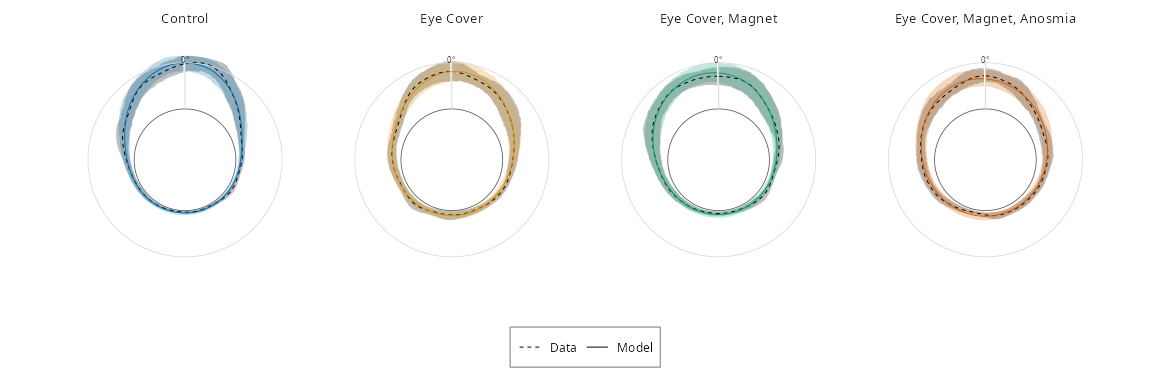

In [51]:
save_figure(p_population_ppc, "bat_population_ppc_by_treatment", 10.5, 3.4)


The individual predictive panels ask the same question for each bat. A good treatment-level average can conceal a poor fit to a particular animal, especially when individuals differ strongly. Compare the observed bootstrap density with the distributions of simulated bearings, looking for a peak that is shifted, too broad, or accompanied by tails the model fails to reproduce.

Read these checks alongside the earlier individual model comparisons. Together they show where the mixture improves prediction and whether it captures the observed distribution. Sparse tracks leave more uncertainty about such details than well-sampled tracks.


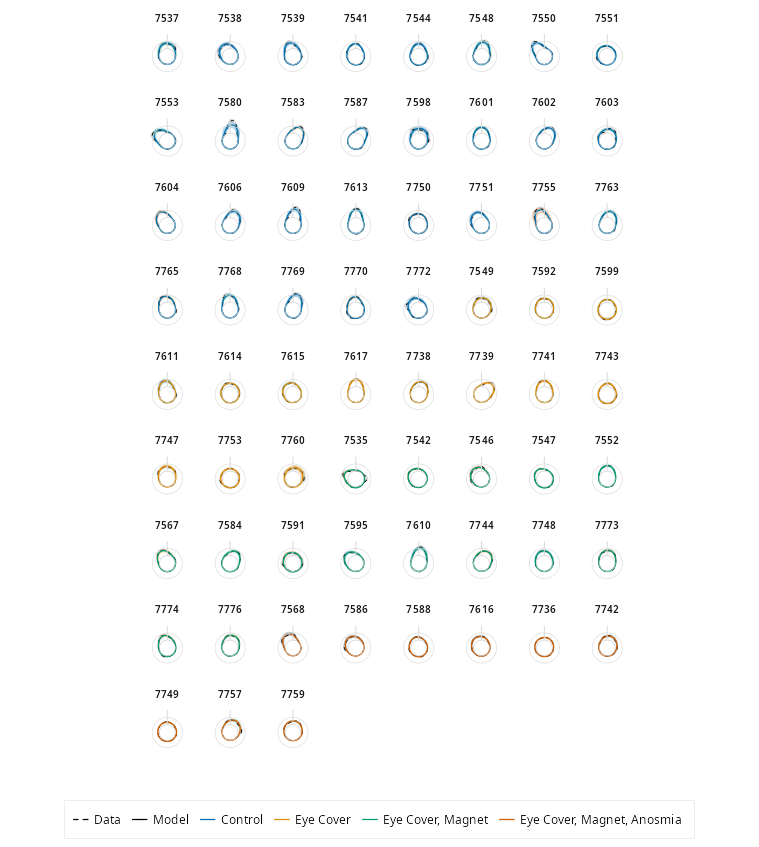

In [52]:
save_figure(p_individual_ppc, "bat_individual_ppc_bootstrap_vs_ppc_kde", 6.9, 7.7)


## Goal-directed movement along a flight

The mixture describes how much directed and undirected movement occurs within a bat's bearings. We can also return to the trajectory and ask which individual bearings the model is most likely to assign to directed travel. This connects the fitted distribution to the possibility that a bat searches early in a flight and becomes more directed later.

Before seeing a particular bearing, the directed-component probability is the bat's mixture weight $\omega_i$. After observing $\varepsilon_{ij}$, the probability becomes

$$
r_{ij}
=\frac{\omega_i\,\mathcal M(\varepsilon_{ij}\mid\mu_i,\kappa_i)}
{\omega_i\,\mathcal M(\varepsilon_{ij}\mid\mu_i,\kappa_i)+(1-\omega_i)/(2\pi)}.
$$

This is the **posterior directed-component probability**. A bearing near the fitted directed peak raises its inferred probability of directed travel; a bearing in the broad background can lower it. The trajectory figures below use posterior directedness, introduced next. This score compares the two component densities with equal prior weights, allowing the same kind of comparison across bats with different fitted mixture weights.

The weight is constant within each bat, but the probability for an individual bearing changes with the observed angle. We infer it from the directional data and then place it back along the track. It is a model-based interpretation of movement, rather than a separately observed decision to begin homing or a probability of eventual arrival.


### Posterior directedness: the component densities, baseline-adjusted

The directed-component probability above also carries each animal's fitted baseline weight $p_i$: where $p_i$ is high, most heading mass is expected to belong to the directed component, so the per-step probability stays elevated even for headings that the two components explain almost equally well. To compare where the directed component is doing genuine explanatory work across animals and treatments, remove the baseline odds. The posterior odds of component membership factor exactly,

$$
\frac{r_{ij}}{1-r_{ij}}
= \frac{p_i}{1-p_i}
  \cdot
  \frac{\mathcal M(y_{ij}\mid\mu_i,\kappa_i)}{1/(2\pi)},
$$

Removing the baseline odds gives the component-density ratio $B_{ij}$. We express **posterior directedness** on a 0–1 scale as $E_{ij}=B_{ij}/(1+B_{ij})$, corresponding to equal prior weights for the two components. Evaluated per posterior draw, with the parameters of that draw kept together and the exact uniform-circle background (the additive constant $\log 2\pi$ cancels),

$$
E_{ij}
= \operatorname{logistic}\!\left(\kappa_i\cos(\theta_{ij}-\mu_i) - \log I_0(\kappa_i)\right),
$$

with $0.5$ meaning equal evidence for the two components. Summaries over draws are taken of these per-draw scores (posterior mean plus a pointwise 90% credible interval), never of posterior-mean parameters and never as mean membership divided by mean weight, and every panel uses the same fixed 0-1 scale.

Posterior directedness compares the directed and undirected component densities after removing each bat's fitted baseline weight; a value of 0.5 indicates equal support for the two components. It is not the fitted probability of directed flight, so it should be read alongside the animal's fitted weight $p_i$ and the oriented-component views elsewhere in this notebook.


In [53]:
set.seed(123)
RESP_DRAWS <- if (quick_run) 200L else 2000L
resp_ids <- sample.int(nd, min(nd, RESP_DRAWS))
resp <- matrix(NA_real_, nrow = nrow(df_track), ncol = length(resp_ids))
evi <- matrix(NA_real_, nrow = nrow(df_track), ncol = length(resp_ids))
logB <- matrix(NA_real_, nrow = nrow(df_track), ncol = length(resp_ids))
for (start in seq.int(1L, nrow(df_track), by = 128L)) {
  ii <- seq.int(start, min(start + 127L, nrow(df_track)))
  par <- response_parameters(fit_mix, df_track[ii, ], mixture = TRUE, draw_ids = resp_ids)
  y <- matrix(rep(df_track$HeadingRadians[ii], length(resp_ids)), nrow = length(ii))
  # Match the effective append_pgoal_post_to_df helper called by the
  # Python notebook: a near-uniform VM proxy and probability-space
  # posterior summaries (the original "Directed-component probability"
  # view, kept verbatim).
  w <- pmin(1 - 1e-12, pmax(1e-12, par$p))
  log_goal <- vm_logpdf(y, par$mu, par$kappa)
  log_flat <- vm_logpdf(y, 0, KAPPA_UNIFORM)
  resp[ii, ] <- plogis(qlogis(w) + log_goal - log_flat)
  # Posterior directedness E on the SAME draws (parameters of one draw
  # kept together); summaries are taken of the per-draw transformed
  # score, never of posterior-mean parameters.
  logB[ii, ] <- log_evid_ratio(y, par$mu, par$kappa)
  evi[ii, ] <- plogis(logB[ii, ])
}
stopifnot(all(is.finite(resp)), all(resp >= 0 & resp <= 1),
  all(is.finite(evi)), all(evi >= 0 & evi <= 1))
# The earlier unused helper has a different logit-space convention; use
# the later effective helper that the Python notebook actually calls.
df_track$p_goal_post_mean <- rowMeans(resp)
resp_hdi <- t(apply(resp, 1, hdi))
df_track$p_goal_post_lo <- resp_hdi[, 1]
df_track$p_goal_post_hi <- resp_hdi[, 2]
# Posterior directedness columns: posterior mean of the per-draw E plus a
# pointwise 90% HDI of the transformed scores; evi_logb_gt0 is the
# per-step draw-wise support Pr(logB > 0); input to the descriptive
# candidate-onset rule (notebooks/goldshtein_bats_posthoc.py).
# Not used by any figure in this twin for now.
df_track$evi_post_mean <- rowMeans(evi)
evi_hdi <- t(apply(evi, 1, hdi, 0.90))
df_track$evi_post_lo <- evi_hdi[, 1]
df_track$evi_post_hi <- evi_hdi[, 2]
df_track$evi_logb_gt0 <- rowMeans(logB > 0)
# Display name shared with the Python twin.
EV_LABEL <- "Posterior directedness"
# The maps' source joins by per-tag step index; join by (tag,time) here to
# avoid shifting probabilities at rows removed from the modeling table.
key <- function(tag, time) paste(tag, sprintf("%.12f", time), sep = ":")
stopifnot(!anyDuplicated(key(track_w_treat$tag, track_w_treat$time)))
track_w_treat$p_pg <- NA_real_
track_w_treat$p_ev <- NA_real_
j <- match(key(track_w_treat$tag, track_w_treat$time), key(df_track$tag, df_track$time))
ok <- !is.na(j)
if (!any(ok)) stop("evidence overlay: no map points matched the modeling table (key-format bug?)")
track_w_treat$p_pg[ok] <- df_track$p_goal_post_mean[j[ok]]
track_w_treat$p_ev[ok] <- df_track$evi_post_mean[j[ok]]
cat("probability/evidence overlay: ", sum(ok), " of ", length(j),
  " map points matched the modeling table\n")
segs_pg <- segments_3857(track_w_treat, pcol = "p_ev")
segs_pg <- segs_pg[is.finite(segs_pg$p), , drop = FALSE]
segs_pg$p <- pmin(1, pmax(0, segs_pg$p))
ext_pg <- map_extent(c(list(seg_bounds(segs_pg)), site_bounds), pad = 0.06)


probability/evidence overlay:  4942  of  5072  map points matched the modeling table


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


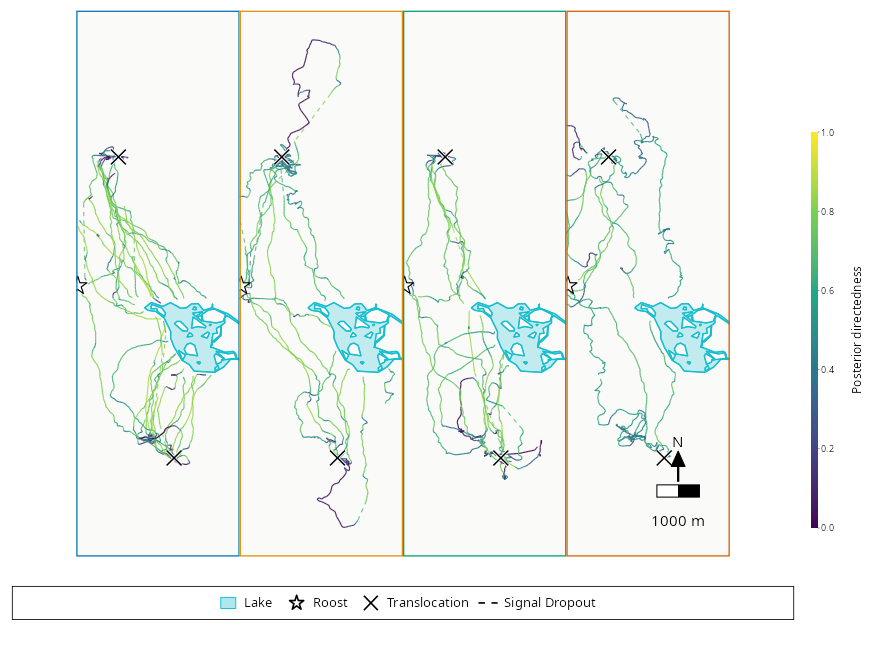

In [54]:
# Tracks colored by each step's posterior directedness (the existing
# viridis scale and fixed 0-1 limits are unchanged; only the encoded
# quantity and the labels change), one panel per treatment on light
# CartoDB Positron tiles with colored panel borders, scale + compass on
# the rightmost panel, a thin right-side colourbar and the bottom figure
# legend - the Python directional-evidence twin.
bm_pg <- basemap_panel_img(ext_pg["xmin"], ext_pg["ymin"],
  ext_pg["xmax"], ext_pg["ymax"], "light_all", 15, "#fafaf8")
# The equal-aspect subplot boxes of the 8x6 figure are ~1.67 x 5.58 in.
ae_pg <- aspect_extent(bm_pg, 1.67 / 5.58)
xlim_pg <- ae_pg$xlim; ylim_pg <- ae_pg$ylim
r_roost_p <- marker_radius_m(200, 1.67, diff(xlim_pg))
r_trans_p <- marker_radius_m(120, 1.67, diff(xlim_pg))
p_probability_map <- directedness_map(segs_pg, bm_pg, xlim_pg, ylim_pg, r_roost_p, r_trans_p)
save_figure(p_probability_map, "treatment_panels_tracks_posterior_directedness", width = 8, height = 6)


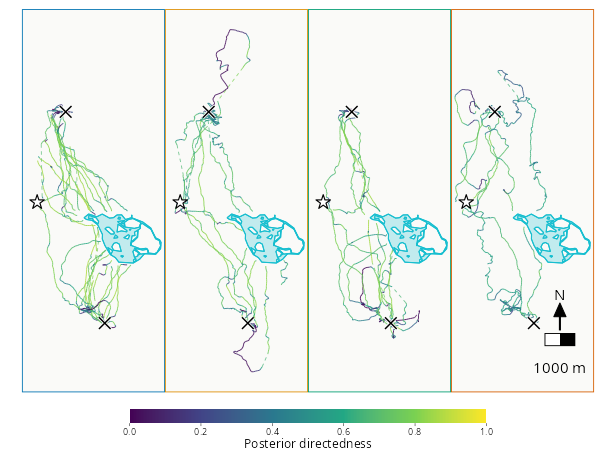

In [55]:
# Compact directional-evidence tracks: smaller figure, the same four
# treatment panels, a wide horizontal colourbar below (no legend) - the
# Python small-fig / bigger-font directional-evidence twin. The existing
# viridis scale and 0-1 limits are unchanged; only the encoded quantity
# and the labels change.
ae_pg_s <- aspect_extent(bm_pg, 1.34 / 3.59)
xlim_pg_s <- ae_pg_s$xlim; ylim_pg_s <- ae_pg_s$ylim
r_roost_ps <- marker_radius_m(105, 1.34, diff(xlim_pg_s))
r_trans_ps <- marker_radius_m(62, 1.34, diff(xlim_pg_s))
p_probability_map_small <- directedness_map_compact(segs_pg, bm_pg, xlim_pg_s, ylim_pg_s, r_roost_ps, r_trans_ps)
save_figure(p_probability_map_small, "treatment_panels_tracks_posterior_directedness_small_bigfont",
  width = 5.6, height = 4.2)


### How does posterior directedness vary along the track?

The curves smooth the per-draw posterior-directedness scores (see above) along each animal's observations. One horizontal axis describes distance to the destination: point distance for the roost, and distance along the local approach-field ray for the lake. This quantity differs from the length of the remaining recorded route.

The other axis, labeled cumulative path distance from the end, counts retained-heading intervals backward from the last retained heading and multiplies by 60 m. It provides an approximate progress coordinate. Missing or excluded rows and tracking gaps mean it should not be treated as exact cumulative distance, elapsed time, or distance to an identified decision event.

Each animal's curve is limited to the region supported by its observations. Population curves average the contributing animal curves equally at each position and are shown only where at least two animals contribute. The population average is then smoothed across neighboring positions. The set of contributing bats can therefore change along the horizontal axis. Posterior means and pointwise 90% intervals of the per-draw scores describe uncertainty carried through the smoothing calculation; they do not include uncertainty from sampling new bats or choosing a different smoothing scale.

The saved curves generally show higher posterior directedness closer to the end of the retained records, with substantial differences among treatments and animals. This is a descriptive pattern in observed headings. It does not establish a common recognition point, a monotonic change for every bat, or a fitted effect of distance on the mixture weight or on the component densities.


In [56]:
# View: posterior directedness, per-draw 90% intervals (see section above).
# make_curves smooths each animal's per-draw scores with a recency-weighted
# trailing exponential window (issue #142, W=10) in recorded-step order, then
# bin-aggregates onto the common x grid (no second Gaussian smoother).
# The original directed-component probability curves are the same calls
# with draws = resp (default hdi_prob 0.95).
distance_curves <- make_curves("distance", evi, hdi_prob = 0.90)
end_curves <- make_curves("steps_from_end", evi, hdi_prob = 0.90)
p_curve_distance <- curve_plot_full(distance_curves, reverse = TRUE)
p_curve_end <- curve_plot_full(end_curves)
p_curve_distance_c <- curve_plot_compact(distance_curves, reverse = TRUE)
p_curve_end_c <- curve_plot_compact(end_curves)
p_tag_distance <- tag_curve_plot(distance_curves, reverse = TRUE)
p_tag_end <- tag_curve_plot(end_curves)


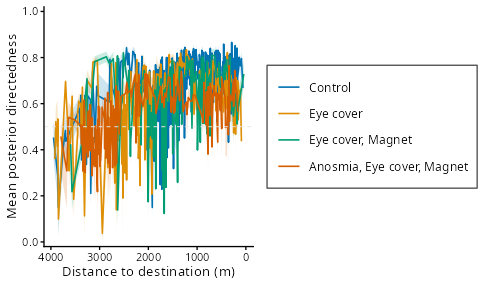

In [57]:
save_figure(p_curve_distance, "posterior_directedness_pop_recencyW10_distance_TRUNC_SMOOTH", 4.4, 2.6)


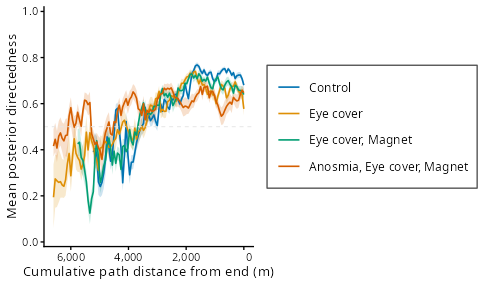

In [58]:
save_figure(p_curve_end, "posterior_directedness_pop_recencyW10_distFromEndM_TRUNC_SMOOTH", 4.4, 2.6)


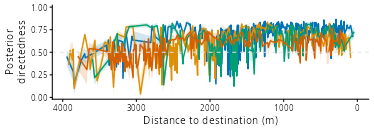

In [59]:
save_figure(p_curve_distance_c, "posterior_directedness_pop_recencyW10_distance_TRUNC_SMOOTH_compact", 3.4, 1.2)


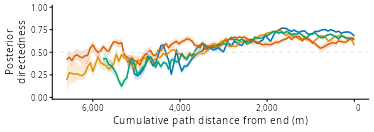

In [60]:
save_figure(p_curve_end_c, "posterior_directedness_pop_recencyW10_distFromEndM_TRUNC_SMOOTH_compact", 3.4, 1.2)


The individual panels show how varied those patterns are. Some animals show sustained posterior directedness across most of their retained headings, while others show fluctuating values or extended low-evidence stretches. Compare each curve only over the range supported by that animal's observations and read its uncertainty together with the number and distribution of headings.



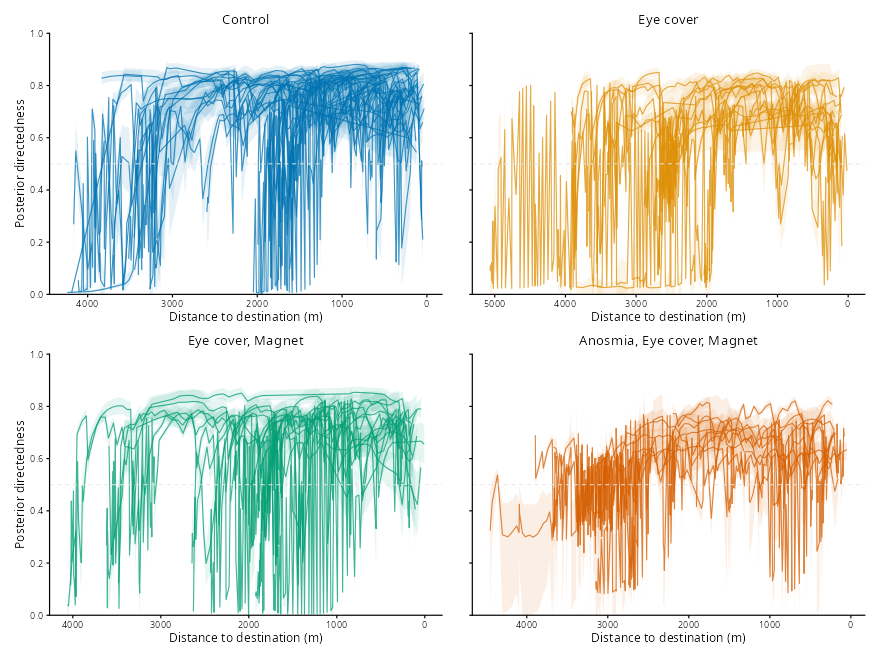

In [61]:
save_figure(p_tag_distance, "posterior_directedness_tag_recencyW10_distance_faceted_TRUNC", 8, 6)


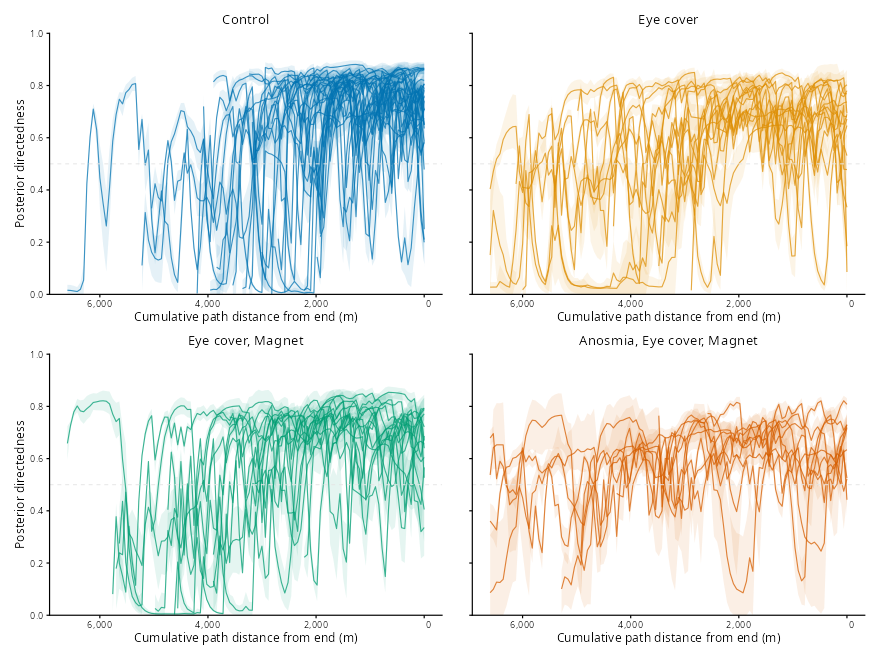

In [62]:
save_figure(p_tag_end, "posterior_directedness_tag_recencyW10_distFromEndM_faceted_TRUNC", 8, 6)


## What the reanalysis tells us about homing

The bats retain a strong tendency to move toward their recorded goals across the sensory conditions. Their flights also contain movement that is poorly represented by one concentrated distribution. The von Mises–uniform mixture predicts the bearings better overall by allowing effectively undirected exploration alongside goal-directed travel, with the improvement concentrated in a subset of bats.

Separating those contributions changes the treatment interpretation. Broad bearings across a whole flight can reflect exploration as well as reduced precision during directed travel. Once the undirected component is represented, the directed component can be more concentrated, but treatment contrasts become more uncertain. Pronounced differences between individual bats make it difficult to attribute the variation to a consistent treatment-wide change in goal-directedness or precision.

The progression curves generally show higher posterior directedness toward the end of retained flights: those bearings receive greater support from the directed component relative to the uniform component. This pattern is consistent with searching giving way to more goal-oriented travel. Individual routes vary substantially around this pattern. Modeling the full usable bearings preserves that variation without selecting a homing subset using features that treatment might itself change.

